In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## 1. Análisis Exploratorio

In [35]:
# abrimos el archivo y vemos el tamaño de nuestro dataset. 
df = pd.read_csv("data/25-testcar-2026-01-21.xlsx - Sheet1.csv")
print(f"las dimensiones del dataset son: {df.shape[0]} filas (registros) x {df.shape[1]} columnas (variables)") 


las dimensiones del dataset son: 4287 filas (registros) x 67 columnas (variables)


In [10]:
df.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,"4,000",RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"3,08","24,8",1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0256000","0,5360000","484,3290000","0,0080000",NaN,"0,0089000","0,0039000","18,3",MPG,"17,8185000","17,0058000","21,6199000",NaN,"-0,1000000","-0,2000000","-0,3500000","53,240","0,22280","0,022100","5,670","0,00830","0,02210",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,"4,000",RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"3,08","24,8",1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,"0,0007000","0,0400000","283,2350000","0,0070000",NaN,NaN,NaN,"31,3",MPG,NaN,NaN,NaN,NaN,"8,7200000","7,0900000","-0,4200000","53,240","0,22280","0,022100","5,670","0,00830","0,02210",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,"4,000",PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,"3,27","22,0",1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0156000","0,1500000","486,7500000","0,0110000","0,0004000","0,0040000",NaN,"18,5",MPG,"17,7311000","17,8284000","20,4728000",NaN,"-0,8400000","-1,0000000","-0,3800000","60,680","-0,32860","0,037300","-4,880","-0,53180","0,03670",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,"4,000",PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,"3,27","22,0",1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0,"0,0200000","331,4800000","0,0030000",NaN,NaN,NaN,"27,2",MPG,NaN,NaN,NaN,NaN,"-5,0300000","-4,1600000","-1,2100000","60,680","-0,32860","0,037300","-4,880","-0,53180","0,03670",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,"5,200",SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"2,93","22,6",1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0170000","0,8260000","546,3510000","0,0250000",NaN,"0,0080000","0,0050000","16,4",MPG,"15,6150000","15,5160000","19,1550000",NaN,"1,6170000","0,9120000","0,0330000","49,170","0,35270","0,022600","-0,570","-0,00290","0,01280",TWC,Three-way catalyst,N,NaN

In [7]:
# para revisar los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   object 
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

In [19]:
df.describe()

,Model Year,Test Veh Configuration #,Rated Horsepower,# of Cylinders and Rotors,# of Gears,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Shift Indicator Light Use Cd,ADFE Equiv. Test Weight (lbs.),Test Procedure Cd,Test Fuel Type Cd
count,4287.0,4287.000000,4287.000000,3617.000000,4287.000000,4287.000000,4287.000000,4287.000000,212.000000,4287.000000,4287.000000
mean,2025.0,0.908328,340.698157,5.222007,6.052018,1.844180,4818.783532,1.073478,4883.254717,36.230231,57.800093
std,0.0,1.255968,175.121581,1.624339,3.397571,0.362727,985.818195,0.475693,706.324859,35.642649,10.737065
min,2025.0,0.000000,1.000000,3.000000,1.000000,1.000000,2750.000000,1.000000,3125.000000,2.000000,19.000000
25%,2025.0,0.000000,201.000000,4.000000,1.000000,2.000000,4000.000000,1.000000,4250.000000,3.000000,61.000000
50%,2025.0,0.000000,305.000000,4.000000,8.000000,2.000000,4750.000000,1.000000,5000.000000,21.000000,61.000000
75%,2025.0,1.000000,409.000000,6.000000,8.000000,2.000000,5500.000000,1.000000,5500.000000,81.000000,61.000000
max,2025.0,8.000000,1948.000000,16.000000,10.000000,2.000000,9000.000000,5.000000,6000.000000,95.000000,62.000000


### Granularidad de los datos

In [51]:
clave = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
print(f"Filas: {len(df)}")
print(f"Configuraciones únicas (clave EPA):", df.groupby(clave).ngroups)
print(f"Filas completamente duplicadas:", df.duplicated().sum())
print(f"Test Number repetidos:", df["Test Number"].duplicated().sum())
print()
print(f"Ensayos por configuración:")
# calcula la frecuencia de ensayo por vehículo. Cuantos vehículos tiene 1 ensayo, 2 ensayos, y así
print(df.groupby(clave).size().value_counts().sort_index())
print()
# muestra los ensayos según categoria o protocolo aplicado
print(df["Test Category"].value_counts())

Filas: 4287
Configuraciones únicas (clave EPA): 1448
Filas completamente duplicadas: 0
Test Number repetidos: 273

Ensayos por configuración:
1     155
2     766
3     118
4     132
5     149
6      54
7      22
8      12
9      20
10     14
12      4
15      1
16      1
Name: count, dtype: int64

Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64


## 2. Limpieza

In [7]:
# isna nos indica si un valor es un NaN o no. COn el sum tomamos todos estos números
# Determinamos cuantos nans hay
df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

podemos ver que los valores nulos en este conjunto son No averaging. Entonces para limpiar la base lo que vamos a hacer es reemplazar todas las ocurrencias de "No averaging" por NaN

In [37]:
# copiamos el conjunto para preservarlo
preprocessed_dataset= df.copy()

In [16]:
preprocessed_dataset.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

#### Busqueda de nulos no estandarizados

In [8]:
# 1. Búsqueda de nulos no estandarizados en columnas tipo object
print("Valores sospechosos en variables de texto:")
for col in df.select_dtypes(include='object').columns:
    sospechosos = df[col].isin(['-1', 'Unknown', 'Unknown / Non-Applicable', 'N/A', '']).sum()
    if sospechosos > 0:
        print(f" - {col}: {sospechosos} registros")

# 2. Control de filas duplicadas exactas
print("\nFilas exactamente duplicadas en la base:", df.duplicated().sum())

# 3. Inspección de la clave única de vehículo
clave_vehiculo = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']
configuraciones_unicas = df.groupby(clave_vehiculo).ngroups
print("Cantidad de configuraciones únicas de vehículos:", configuraciones_unicas)
print("Cantidad total de ensayos registrados:", len(df))

Valores sospechosos en variables de texto:

Filas exactamente duplicadas en la base: 0
Cantidad de configuraciones únicas de vehículos: 1448
Cantidad total de ensayos registrados: 4287


C:\Users\santy\AppData\Local\Temp\ipykernel_20144\1294798436.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


#### Conversión de tipos de datos en variables categóricas

Se convierten las columnas `Test Veh Configuration #`, `Transmission Overdrive Code`, `Shift Indicator Light Use Cd`, `Test Procedure Cd` y `Test Fuel Type Cd` de tipo entero (`int64`) a tipo texto (`object`).

**Justificación:** Aunque están registradas numéricamente en el archivo original, estas variables representan códigos categóricos nominales sin orden ni magnitud matemática. Mantenerlas como enteros constituye una infracción de tipo de dato y distorsionaría los análisis estadísticos cuantitativos.

In [4]:
columnas_categoricas = [
    'Test Veh Configuration #',
    'Transmission Overdrive Code',
    'Shift Indicator Light Use Cd',
    'Test Procedure Cd',
    'Test Fuel Type Cd',
]

preprocessed_dataset[columnas_categoricas] = preprocessed_dataset[columnas_categoricas].astype(str)

#### Eliminación de columnas sin variabilidad

Se elimina la columna `Model Year` del dataset.

**Justificación:** Todos los registros corresponden al valor constante `2025`. Al presentar varianza nula, esta columna no aporta información descriptiva ni discriminatoria para los análisis.

In [5]:
# Eliminación de la columna sin variabilidad
preprocessed_dataset = preprocessed_dataset.drop(columns=['Model Year'])

Se elimina la columna `FE_UNIT` del dataset.

**Justificación:** Todos los registros corresponden al valor constante `MPG`. Al presentar varianza nula, esta columna no aporta información descriptiva ni discriminatoria para los análisis.

In [49]:
preprocessed_dataset = preprocessed_dataset.drop(columns=['FE_UNIT'])

#### Conversión de variables categóricas binarias (Y/N) a booleanas (True/False).

Al presentar únicamente dos valores ('Y' y 'N'), estas columnas constituyen variables binarias. Mapearlas a valores booleanos (True / False) permite expresar correctamente su naturaleza estadística y evita confusiones durante la manipulación y el análisis de los datos.

In [7]:
cols_binarias = [
    'Transmission Lockup?',
    'Analytically Derived FE?',
    'Police - Emergency Vehicle?',
]

for col in cols_binarias:
    preprocessed_dataset[col] = preprocessed_dataset[col] == 'Y'

#### Limpieza y Analisis de variables

##### Variables categóricas

In [50]:
import matplotlib.pyplot as plt

def graficar_frecuencias(columna):
    frecuencias = preprocessed_dataset[columna].value_counts(
        normalize=True
    ) * 100

    frecuencias.plot(kind='bar', figsize=(10, 5))

    plt.title(f'Distribución de {columna}')
    plt.xlabel('Categorías')
    plt.ylabel('Porcentaje (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

###### Test Fuel Type Description

Combustible/fuente de energía utilizada.

In [52]:
preprocessed_dataset['Test Fuel Type Description'].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

In [58]:
preprocessed_dataset['Test Fuel Type Description'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Test Fuel Type Description
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [62]:
preprocessed_dataset['Test Fuel Type Description'].isna().sum()

np.int64(0)

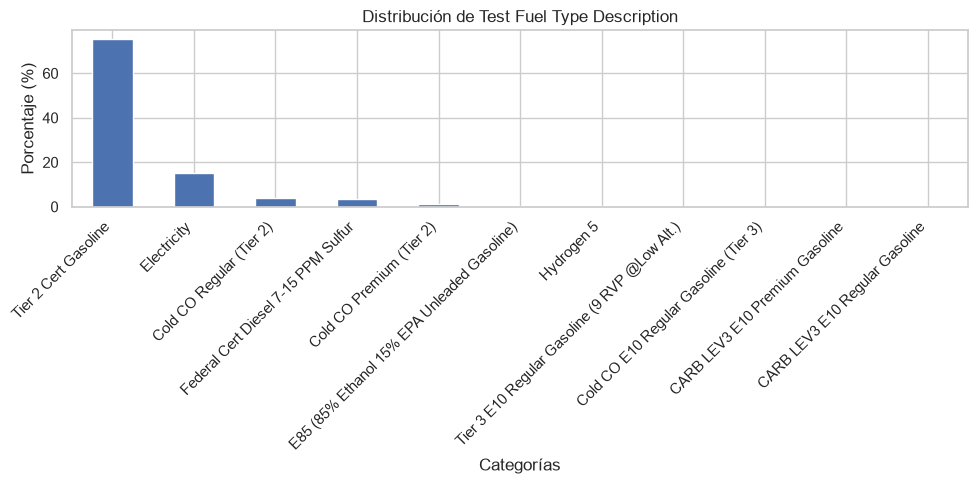

In [59]:
graficar_frecuencias('Test Fuel Type Description')

A partir del gráfico podemos observar que existe un claro predominio de la gasolina estándar (Tier 2 Cert Gasoline), que representa aproximadamente el 75,48 % de los registros. En segundo lugar, se encuentra la electricidad, con un 15,26 %, aunque con una participación considerablemente menor.

###### Drive System Code

Código de tracción.

In [61]:
preprocessed_dataset['Drive System Code'].value_counts()

Drive System Code
A    1459
F    1393
R     957
4     405
P      73
Name: count, dtype: int64

In [63]:
preprocessed_dataset['Drive System Code'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Drive System Code
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [64]:
preprocessed_dataset['Drive System Code'].isna().sum()

np.int64(0)

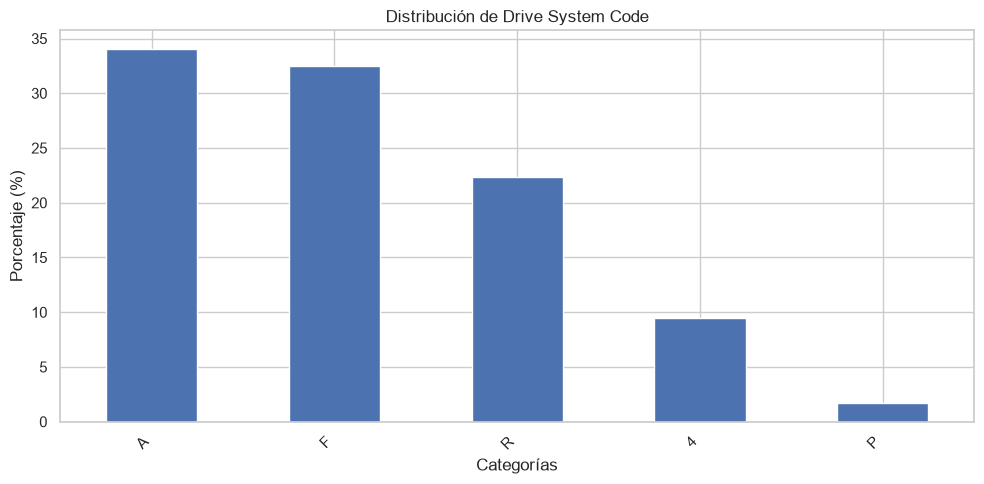

In [65]:
graficar_frecuencias('Drive System Code')

A partir del gráfico, podemos observar que los sistemas de tracción menos habituales son:
- P (Part-time 4WD): es el menos frecuente, con aproximadamente un 1,7 % de los registros. Corresponde a la tracción en las cuatro ruedas conectable.
- 4 (4WD): presenta una frecuencia cercana al 9,4 %, por lo que también tiene una participación considerablemente menor que los sistemas predominantes.

###### Tested Transmission Type

Automática, manual, semiautomática, CVT, etc.

In [66]:
preprocessed_dataset['Tested Transmission Type'].value_counts()

Tested Transmission Type
Automatic                                                            1639
Semi-Automatic                                                       1220
Continuously Variable                                                 490
Automated Manual- Selectable (e.g. Automated Manual with paddles)     485
Selectable Continuously Variable (e.g. CVT with paddles)              171
Manual                                                                128
Other                                                                 102
Automated Manual                                                       52
Name: count, dtype: int64

In [67]:
preprocessed_dataset['Tested Transmission Type'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Tested Transmission Type
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [68]:
preprocessed_dataset['Tested Transmission Type'].isna().sum()

np.int64(0)

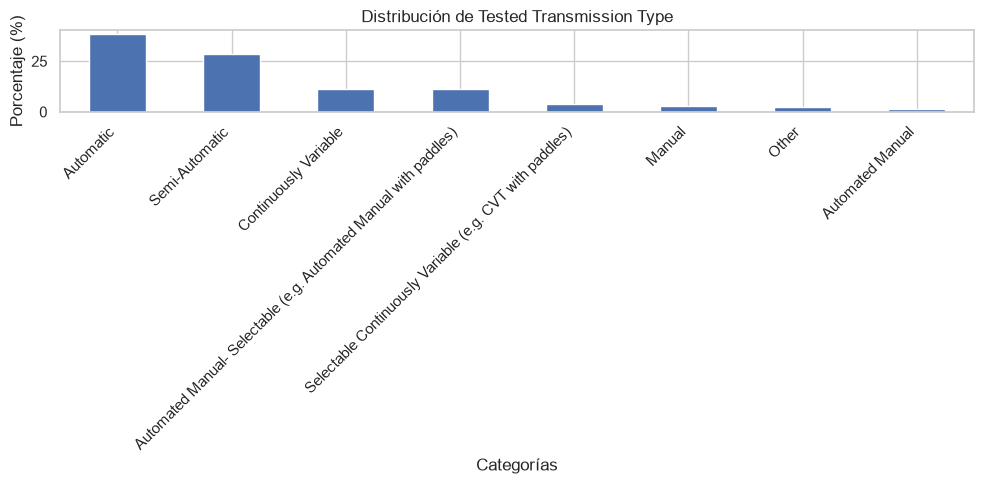

In [69]:
graficar_frecuencias('Tested Transmission Type')

A partir de los datos, podemos observar que los tipos de transmisión menos frecuentes son Automated Manual, con 52 registros (1,21 %), Other, con 102 registros (2,38 %), y Manual (tradicional), con 128 registros (2,99 %).

###### Vehicle Type

Car, Truck o Both.

In [73]:
preprocessed_dataset['Vehicle Type'].value_counts()

Vehicle Type
Truck    2030
Car      1631
Both      626
Name: count, dtype: int64

In [74]:
preprocessed_dataset['Vehicle Type'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Vehicle Type
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [75]:
preprocessed_dataset['Vehicle Type'].isna().sum()

np.int64(0)

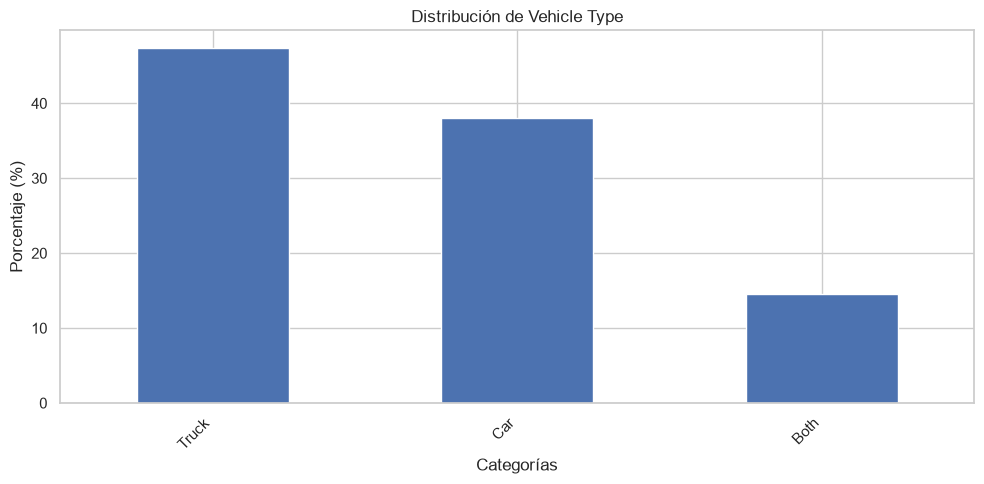

In [76]:
graficar_frecuencias('Vehicle Type')

###### Test Category

Categoría resumida del ensayo.

In [78]:
preprocessed_dataset['Test Category'].value_counts()

Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64

In [79]:
preprocessed_dataset['Test Category'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Test Category
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [80]:
preprocessed_dataset['Test Category'].isna().sum()

np.int64(0)

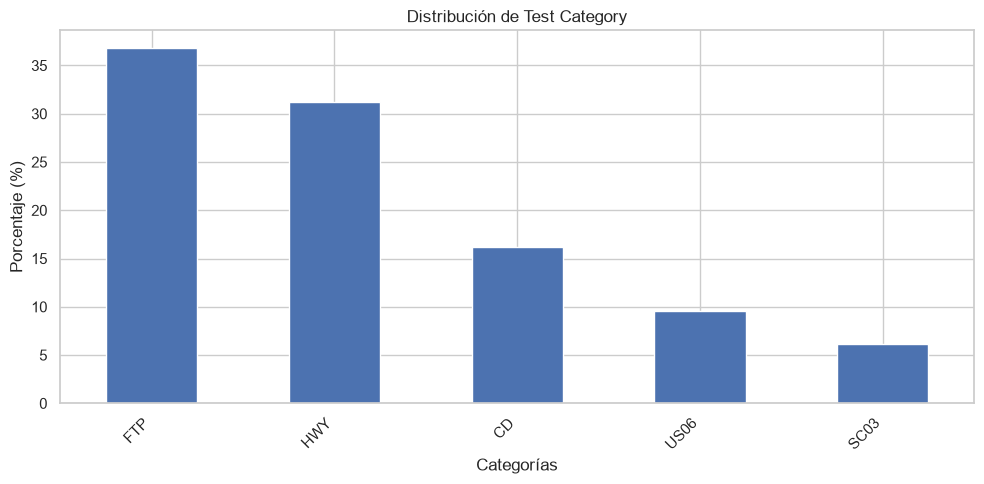

In [81]:
graficar_frecuencias('Test Category')

En general, todas las categorías cuentan con una representación considerable, por lo que no se identifican categorías con frecuencias extremadamente bajas.

###### Vehicle Manufacturer Name

Fabricante del vehículo.

In [82]:
preprocessed_dataset['Vehicle Manufacturer Name'].value_counts()

Vehicle Manufacturer Name
GM                      697
BMW                     597
Toyota                  523
Hyundai                 317
Volkswagen Group of     280
FOMOCO                  255
Mercedes-Benz           205
Nissan                  191
Kia                     167
Porsche                 152
Honda                   144
FCA US LLC              131
MAZDA                    82
Jaguar Land Rover L      79
Rivian Automotive L      77
Subaru                   68
Volvo                    67
Ferrari                  50
Tesla                    43
Maserati                 31
Mitsubishi Motors Co     25
Wuhan Lotus Cars Co      24
Lucid USA, Inc           20
Vinfast Trading and      20
Rolls-Royce              10
aston martin              8
Lotus                     8
Ineos Automotive Li       6
Karma Automotive          4
Bugatti Rimac LLC         2
CZV Inc                   2
Pagani S.p.A.             2
Name: count, dtype: int64

In [83]:
preprocessed_dataset['Vehicle Manufacturer Name'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Vehicle Manufacturer Name
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [84]:
preprocessed_dataset['Vehicle Manufacturer Name'].isna().sum()

np.int64(0)

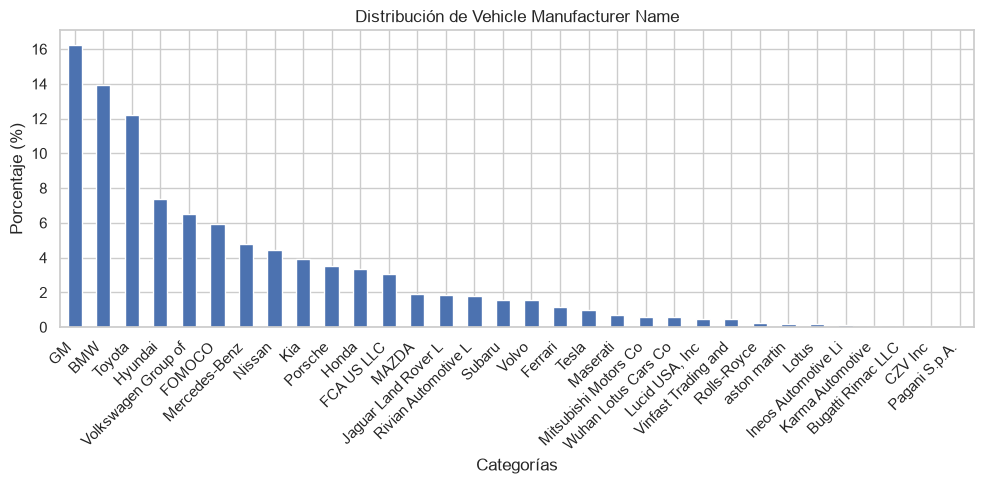

In [85]:
graficar_frecuencias('Vehicle Manufacturer Name')

se observa una distribución desigual entre los fabricantes: mientras algunos concentran una gran cantidad de ensayos, otros tienen una representación muy reducida. Estos últimos pueden considerarse posibles outliers categóricos debido a su baja frecuencia dentro del dataset. Sin embargo, su escasa presencia no implica que los registros sean incorrectos, sino que corresponden a fabricantes con menor representación en la muestra.

###### Engine Code

Código del motor.

In [86]:
preprocessed_dataset['Engine Code'].value_counts()

Engine Code
1       281
01      212
2       102
03       92
02       91
       ... 
L1Y       1
GOTI      1
PA_1      1
PB_1      1
EV_1      1
Name: count, Length: 523, dtype: int64

In [87]:
preprocessed_dataset['Engine Code'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Engine Code
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [88]:
preprocessed_dataset['Engine Code'].isna().sum()

np.int64(0)

La variable Engine Code presenta una elevada cardinalidad, con 523 categorías distintas. Si bien algunos códigos concentran una mayor cantidad de registros, existe una gran cantidad de configuraciones de motor con frecuencias muy bajas, incluso de un único registro. Esta diversidad puede explicarse por la variedad de vehículos y fabricantes incluidos en el dataset. Por este motivo, no se considera que la presencia de numerosos códigos constituya un problema de calidad de datos por sí misma, aunque sí representa una dificultad para su análisis estadístico. No se recomienda eliminar estas categorías únicamente por su baja frecuencia, ya que podrían representar configuraciones de motor válidas y específicas.

##### Variables numéricas

In [102]:
import matplotlib.pyplot as plt

def graficar_boxplot(columna):
    plt.figure(figsize=(8, 4))

    preprocessed_dataset.boxplot(column=columna)

    plt.title(f'Boxplot de {columna}')
    plt.ylabel(columna)
    plt.show()

###### Test Veh Displacement (L)

Cilindrada del motor.

In [91]:
preprocessed_dataset['Test Veh Displacement (L)'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Test Veh Displacement (L)
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


In [106]:
preprocessed_dataset['Test Veh Displacement (L)'].value_counts()

Test Veh Displacement (L)
2,000     659
0,001     518
3,000     516
2,500     306
2,487     206
3,500     164
1,600     157
5,300     119
2,700     111
1,500     110
4,400      96
99,999     95
3,600      86
2,393      84
1,987      82
4,000      63
6,200      63
3,982      61
2,900      53
5,500      53
2,400      48
0,010      47
2,999      44
3,445      44
2,300      42
5,000      40
1,991      38
1,999      37
1,969      35
3,456      31
3,300      30
1,200      30
3,800      30
1,984      30
1,300      25
1,798      20
3,900      18
6,500      16
4,969      14
5,200      10
3,700       8
3,996       7
5,700       6
2,998       6
1,498       5
1,998       4
1,618       4
6,400       2
5,980       2
99,990      2
6,000       2
6,700       2
1,000       2
7,993       2
6,498       2
Name: count, dtype: int64

Notamos que la variable `Test Veh Displacement (L)` es de tipo str, asi que la cambiamos a tipo float. Hacemos esto porque esta variable representa la cilindrada del motor en litros, una magnitud numérica que puede contener valores decimales (por ejemplo, 1.5, 2.0 o 3.6).

Esto permite realizar correctamente operaciones matemáticas y análisis estadísticos, como calcular promedios, medianas y detectar valores atípicos.

In [92]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
preprocessed_dataset["Test Veh Displacement (L)"] = (preprocessed_dataset["Test Veh Displacement (L)"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
preprocessed_dataset["Test Veh Displacement (L)"] = pd.to_numeric(preprocessed_dataset["Test Veh Displacement (L)"], errors="coerce")


In [101]:
preprocessed_dataset["Test Veh Displacement (L)"].describe()

count    4190.000000
mean        2.481663
std         1.428514
min         0.001000
25%         1.987000
50%         2.487000
75%         3.000000
max         7.993000
Name: Test Veh Displacement (L), dtype: float64

Se identificaron dos valores extremadamente elevados en la variable Test Veh Displacement (L), correspondientes a 99.999 y 99.990 litros. Debido a que resultaban inconsistentes con las cilindradas habituales de los vehículos, se decidió reemplazarlos por valores faltantes (NaN) para evitar que distorsionaran los análisis estadísticos posteriores.

In [100]:
# Reemplazar valores extremos por NaN
valores_invalidos = [99999, 99990]

preprocessed_dataset['Test Veh Displacement (L)'] = (preprocessed_dataset['Test Veh Displacement (L)'].replace(valores_invalidos, np.nan))

In [107]:
preprocessed_dataset['Test Veh Displacement (L)'].isna().sum()

np.int64(97)

Los nulos se deben a los valores extremos que eliminamos

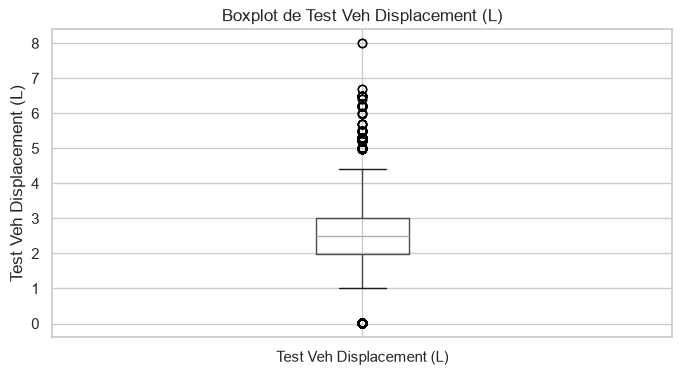

In [108]:
graficar_boxplot('Test Veh Displacement (L)')

###### Rated Horsepower

Potencia nominal.

In [112]:
preprocessed_dataset['Rated Horsepower'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Rated Horsepower
Non-Null Count  Dtype
--------------  -----
4287 non-null   int64
dtypes: int64(1)
memory usage: 33.6 KB


In [113]:
preprocessed_dataset['Rated Horsepower'].value_counts()

Rated Horsepower
305    162
375    141
255    130
355    128
400    103
      ... 
595      1
641      1
579      1
390      1
296      1
Name: count, Length: 244, dtype: int64

In [115]:
preprocessed_dataset['Rated Horsepower'].describe()

count    4287.000000
mean      340.698157
std       175.121581
min         1.000000
25%       201.000000
50%       305.000000
75%       409.000000
max      1948.000000
Name: Rated Horsepower, dtype: float64

In [116]:
preprocessed_dataset['Rated Horsepower'].isna().sum()

np.int64(0)

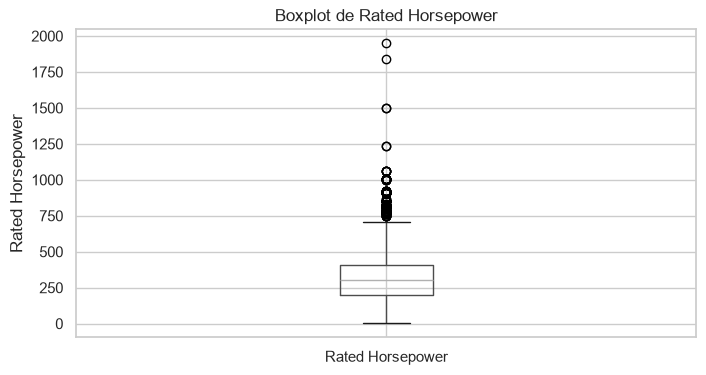

In [117]:
graficar_boxplot('Rated Horsepower')

In [118]:
# 1. Calcular cuartiles e IQR
q1 = preprocessed_dataset['Rated Horsepower'].quantile(0.25)
q3 = preprocessed_dataset['Rated Horsepower'].quantile(0.75)
iqr = q3 - q1

# 2. Calcular límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# 3. Identificar valores atípicos
outliers = preprocessed_dataset[
    (preprocessed_dataset['Rated Horsepower'] < limite_inferior) |
    (preprocessed_dataset['Rated Horsepower'] > limite_superior)
]

# 4. Mostrar resultados
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")
print(f"Cantidad de outliers: {len(outliers)}")

# 5. Mostrar información de los vehículos
display(outliers[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Rated Horsepower',
    'Test Vehicle ID'
]].sort_values('Rated Horsepower', ascending=False))

Límite inferior: -111.0
Límite superior: 721.0
Cantidad de outliers: 141


,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Rated Horsepower,Test Vehicle ID
606,Bugatti Rimac LLC,Bugatti Rimac,Nevera R,1948,V39B12RZXS5AB8001
605,Bugatti Rimac LLC,Bugatti Rimac,Nevera,1839,V39X22AZ9M3AB8004
4117,Volkswagen Group of,BUGATTI,Bugatti Pur Sport,1500,BG744-PT50 CHIRON R
4116,Volkswagen Group of,BUGATTI,Bugatti Pur Sport,1500,BG744-PT50 CHIRON R
2468,"Lucid USA, Inc",2024,Air Sapphire AWD,1234,202400084
...,...,...,...,...,...
2487,Maserati,Maserati,Grancabrio Folgore,751,436805
2493,Maserati,Maserati,Granturismo Folgore,751,436805
2492,Maserati,Maserati,Granturismo Folgore,751,436805
608,CZV Inc,Czinger,21C,750,4C9PBPEKXRL561002


Mediante el método del rango intercuartílico (IQR), se identificaron 141 posibles valores atípicos en la variable Rated Horsepower. El límite inferior obtenido fue de -111 HP y el superior de 721 HP. Al investigar los registros con mayores potencias, se encontraron vehículos deportivos y eléctricos de altas prestaciones, como Bugatti Nevera R, Bugatti Chiron Pur Sport y Lucid Air Sapphire. Esto demuestra que algunos valores identificados como atípicos responden a características reales de determinados vehículos y no necesariamente a errores de carga. Por este motivo, se decidió no reemplazarlos automáticamente por valores faltantes.

###### # of Cylinders and Rotors

Número de cilindros o rotores.

In [119]:
preprocessed_dataset['# of Cylinders and Rotors'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: # of Cylinders and Rotors
Non-Null Count  Dtype  
--------------  -----  
3617 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


In [120]:
preprocessed_dataset['# of Cylinders and Rotors'].value_counts()

# of Cylinders and Rotors
4.0     1903
6.0     1048
8.0      544
3.0       89
12.0      26
5.0        5
16.0       2
Name: count, dtype: int64

In [121]:
preprocessed_dataset['# of Cylinders and Rotors'].describe()

count    3617.000000
mean        5.222007
std         1.624339
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64

In [122]:
preprocessed_dataset['# of Cylinders and Rotors'].isna().sum()

np.int64(670)

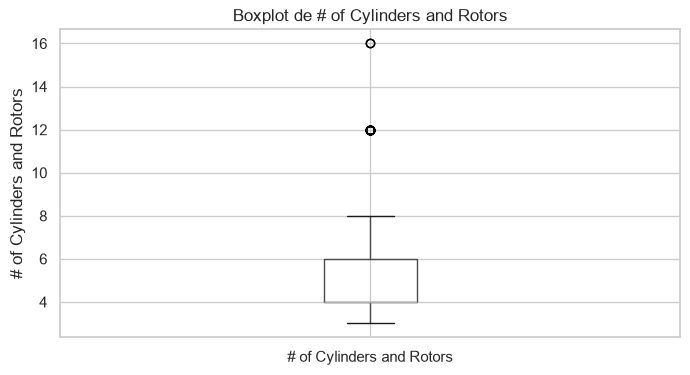

In [123]:
graficar_boxplot('# of Cylinders and Rotors')

###### Equivalent Test Weight (lbs.)

representa el **peso equivalente de prueba del vehículo**, expresado en **libras (lb)**

In [125]:
preprocessed_dataset['Equivalent Test Weight (lbs.)'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Equivalent Test Weight (lbs.)
Non-Null Count  Dtype
--------------  -----
4287 non-null   int64
dtypes: int64(1)
memory usage: 33.6 KB


In [126]:
preprocessed_dataset['Equivalent Test Weight (lbs.)'].value_counts()

Equivalent Test Weight (lbs.)
5500    515
4250    446
6000    428
4750    389
5000    347
4500    339
4000    339
5250    274
6500    223
3875    205
3500    178
3375    137
3750    133
3625    110
7000     89
3250     60
3000     18
3125     13
7500     13
9000     12
8500      8
2875      4
2750      4
8000      3
Name: count, dtype: int64

In [127]:
preprocessed_dataset['Equivalent Test Weight (lbs.)'].describe()

count    4287.000000
mean     4818.783532
std       985.818195
min      2750.000000
25%      4000.000000
50%      4750.000000
75%      5500.000000
max      9000.000000
Name: Equivalent Test Weight (lbs.), dtype: float64

In [128]:
preprocessed_dataset['Equivalent Test Weight (lbs.)'].isna().sum()

np.int64(0)

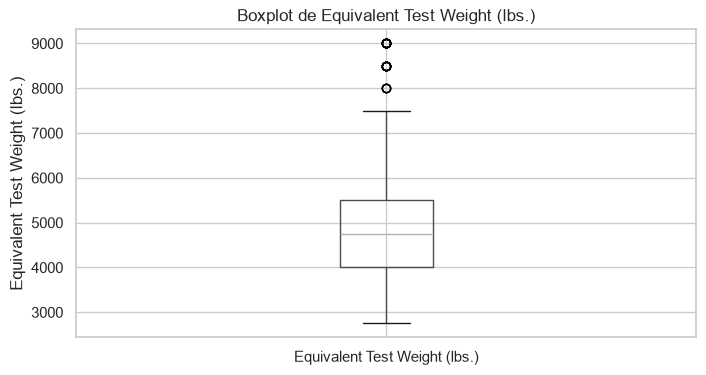

In [129]:
graficar_boxplot('Equivalent Test Weight (lbs.)')

In [133]:
# 1. Calcular cuartiles e IQR
q1 = preprocessed_dataset['Equivalent Test Weight (lbs.)'].quantile(0.25)
q3 = preprocessed_dataset['Equivalent Test Weight (lbs.)'].quantile(0.75)
iqr = q3 - q1

# 2. Calcular límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# 3. Identificar valores atípicos
outliers = preprocessed_dataset[
    (preprocessed_dataset['Equivalent Test Weight (lbs.)'] < limite_inferior) |
    (preprocessed_dataset['Equivalent Test Weight (lbs.)'] > limite_superior)
]

# 4. Mostrar resultados
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")
print(f"Cantidad de outliers: {len(outliers)}")

# 5. Mostrar información de los vehículos
display(outliers[[
    'Vehicle Type',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Equivalent Test Weight (lbs.)',
    'Test Vehicle ID'
]].sort_values('Equivalent Test Weight (lbs.)', ascending=False))

Límite inferior: 1750.0
Límite superior: 7750.0
Cantidad de outliers: 23


,Vehicle Type,Represented Test Veh Make,Represented Test Veh Model,Equivalent Test Weight (lbs.),Test Vehicle ID
1454,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1453,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1452,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1458,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E277
1457,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1456,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1455,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1731,Truck,GMC,SIERRA EV,9000,3SETE272
1600,Truck,GMC,HUMMER EV SUV,9000,HSSTC492
1596,Truck,GMC,HUMMER EV PICKUP,9000,HSSTB483


los valores atípicos identificados corresponden a vehículos clasificados como Truck, principalmente camionetas eléctricas de gran porte, como la Chevrolet Silverado EV, GMC Sierra EV y GMC Hummer EV. Sus elevados pesos de ensayo se justifican por las características propias de este tipo de vehículos. Por lo tanto, se decidió conservar estos registros, ya que no representan necesariamente errores en los datos, sino vehículos de mayor tamaño y peso que se alejan del comportamiento general del dataset.

###### Axle Ratio

Es un parámetro mecánico del ensayo que representa la **relación de eje**.

In [140]:
preprocessed_dataset['Axle Ratio'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Axle Ratio
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


In [148]:
preprocessed_dataset['Axle Ratio'].value_counts()

Axle Ratio
3.23    340
1.00    266
2.81    129
3.42     98
3.73     95
       ... 
4.30      2
3.04      2
9.20      2
2.58      2
2.55      2
Name: count, Length: 161, dtype: int64

Notamos que la variable `Axle Ratio` es de tipo str, asi que la cambiamos a tipo float.Hacemos esto porque es una variable que contiene valores decimales. Este cambio permite realizar operaciones matemáticas y análisis estadísticos, como calcular promedios, medianas y detectar posibles valores atípicos.

In [139]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
preprocessed_dataset["Axle Ratio"] = (preprocessed_dataset["Axle Ratio"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
preprocessed_dataset["Axle Ratio"] = pd.to_numeric(preprocessed_dataset["Axle Ratio"], errors="coerce")

In [149]:
preprocessed_dataset['Axle Ratio'].describe()

count    4169.000000
mean        3.608801
std         1.384319
min         0.000000
25%         3.200000
50%         3.420000
75%         3.800000
max         9.810000
Name: Axle Ratio, dtype: float64

Analizando el valor maximo:

In [144]:
# Filtrar registros con Axle Ratio igual a 9.99
registros_999 = preprocessed_dataset[
    preprocessed_dataset['Axle Ratio'] == 9.99
]

# Mostrar información de los vehículos
display(registros_999[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Vehicle Type',
    'Axle Ratio',
    'Test Vehicle ID'
]])

,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Vehicle Type,Axle Ratio,Test Vehicle ID
636,FCA US LLC,Dodge,Charger 2-Dr Daytona R/T AWD 20in Nexen,Car,9.99,N4LB75749
637,FCA US LLC,Dodge,Charger 2-Dr Daytona Scat Pack Track Pack AWD A/S,Car,9.99,N4LB75563
703,FCA US LLC,Jeep,Wagoneer S AWD (Falken tire),Both,9.99,N4KMX1858
3175,Rivian Automotive L,Rivian,R1S All-Terrain Performance Dual Large (20in),Truck,9.99,R1S378XR20AT
3176,Rivian Automotive L,Rivian,R1S All-Terrain Performance Dual Large (20in),Truck,9.99,R1S378XR20AT
...,...,...,...,...,...,...
4214,Volvo,Polestar,Polestar 4 long range single motor,Car,9.99,202533
4219,Volvo,Volvo,EX30 Single Motor extended range,Car,9.99,202532
4220,Volvo,Volvo,EX30 Single Motor extended range(18 Inch Wheel),Car,9.99,202532
4221,Volvo,Volvo,EX30 Twin Performance (19 Inch Wheels),Car,9.99,202536


Se identificó que el valor 9,99 aparece en 118 registros de la variable Axle Ratio, correspondientes a distintos fabricantes, modelos y tipos de vehículos. Debido a su elevada frecuencia y a su presencia en configuraciones muy diversas, se sospecha que podría tratarse de un código que representa información no disponible o no aplicable.

In [145]:
# Reemplazar el valor 9.99 por NaN
preprocessed_dataset['Axle Ratio'] = (preprocessed_dataset['Axle Ratio'].replace(9.99, np.nan))

In [146]:
preprocessed_dataset['Axle Ratio'].isna().sum()

np.int64(118)

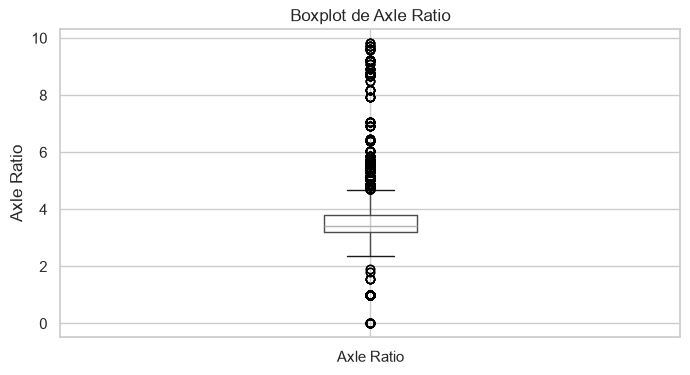

In [147]:
graficar_boxplot('Axle Ratio')

###### N/V Ratio

Es un parámetro mecánico del ensayo que representa la relación entre la velocidad de giro del motor (\\(N\\), en revoluciones) y la velocidad del vehículo (\\(V\\)).

In [156]:
preprocessed_dataset['N/V Ratio'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: N/V Ratio
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


Notamos que es de tipo str, la convertimos en float.

In [155]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
preprocessed_dataset["N/V Ratio"] = (preprocessed_dataset["N/V Ratio"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
preprocessed_dataset["N/V Ratio"] = pd.to_numeric(preprocessed_dataset["N/V Ratio"], errors="coerce")

In [157]:
preprocessed_dataset['N/V Ratio'].value_counts()

N/V Ratio
24.0     176
21.7      92
999.0     91
21.6      82
26.1      77
        ... 
107.5      1
100.8      1
144.4      1
144.2      1
142.2      1
Name: count, Length: 280, dtype: int64

In [166]:
preprocessed_dataset['N/V Ratio'].describe()

count    4196.000000
mean       36.951859
std        32.577028
min         0.000000
25%        23.300000
50%        25.600000
75%        29.300000
max       229.200000
Name: N/V Ratio, dtype: float64

In [163]:
# Filtrar registros con Axle Ratio igual a 999.00
registros_999 = preprocessed_dataset[
    preprocessed_dataset['N/V Ratio'] == 999.00
]

# Mostrar información de los vehículos
display(registros_999[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Vehicle Type',
    'N/V Ratio',
    'Test Vehicle ID',
    'Test Number',
    'Tested Transmission Type',
    'Axle Ratio',
    '# of Gears'
]])

,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Vehicle Type,N/V Ratio,Test Vehicle ID,Test Number,Tested Transmission Type,Axle Ratio,# of Gears
2483,"Lucid USA, Inc",2025,Lucid Gravity GT (2R),Car,999.0,2025G01033,SLMU10088423,Automatic,7.06,1
2484,"Lucid USA, Inc",2025,Lucid Gravity GT (2R),Car,999.0,2025G01033,SLMU10088082,Automatic,7.06,1
2485,"Lucid USA, Inc",2025,Lucid Gravity GT (3R),Car,999.0,2025G01034,SLMU10088084,Automatic,7.06,1
2486,"Lucid USA, Inc",2025,Lucid Gravity GT (3R),Car,999.0,2025G01034,SLMU10088083,Automatic,7.06,1
2487,Maserati,Maserati,Grancabrio Folgore,Car,999.0,436805,SMAX10086837,Other,6.92,1
...,...,...,...,...,...,...,...,...,...,...
3247,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086075,Automatic,NaN,1
3248,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086076,Automatic,NaN,1
3249,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086077,Automatic,NaN,1
3250,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086078,Automatic,NaN,1


Durante el análisis de la variable N/V Ratio, se identificó el valor 999 como un posible código especial, debido a que se encuentra muy alejado de los valores habituales de la variable. Al investigar los registros asociados, se observó que aparece en vehículos eléctricos de distintos fabricantes, como Lucid, Maserati y Rivian, que presentan una única marcha. Esto sugiere que podría tratarse de un valor utilizado para representar una relación no disponible o no aplicable. Por este motivo, se decidió investigar su significado en la metadata antes de determinar su reemplazo por un valor faltante (NaN).

In [164]:
# Reemplazar el valor 999.00 por NaN
preprocessed_dataset['N/V Ratio'] = (preprocessed_dataset['N/V Ratio'].replace(999.00, np.nan))

In [165]:
preprocessed_dataset['N/V Ratio'].isna().sum()

np.int64(91)

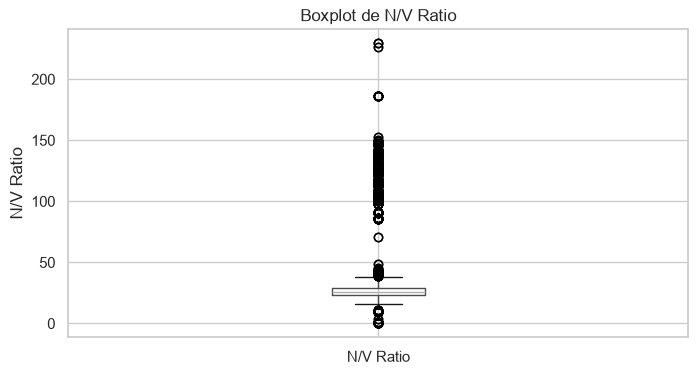

In [167]:
graficar_boxplot('N/V Ratio')

#### Analizando datos

In [2]:
!pip install sweetviz


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\santy\Fundamentos\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Feature: Model Year                          |▏         | [  1%]   00:00 -> (00:12 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: Vehicle Manufacturer Name           |▎         | [  3%]   00:00 -> (00:26 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
F


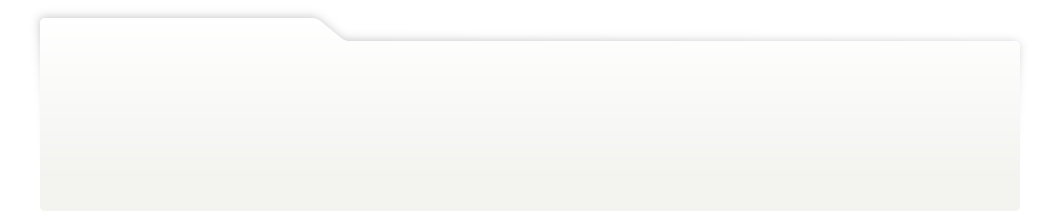
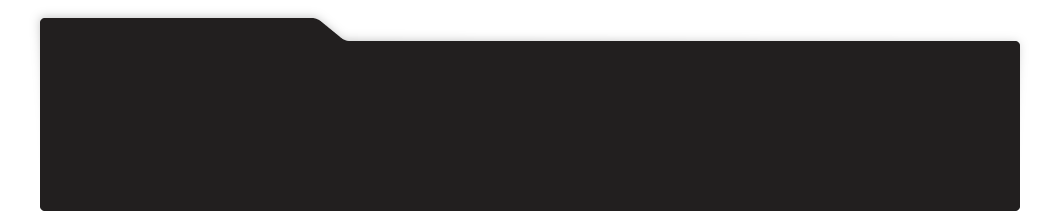
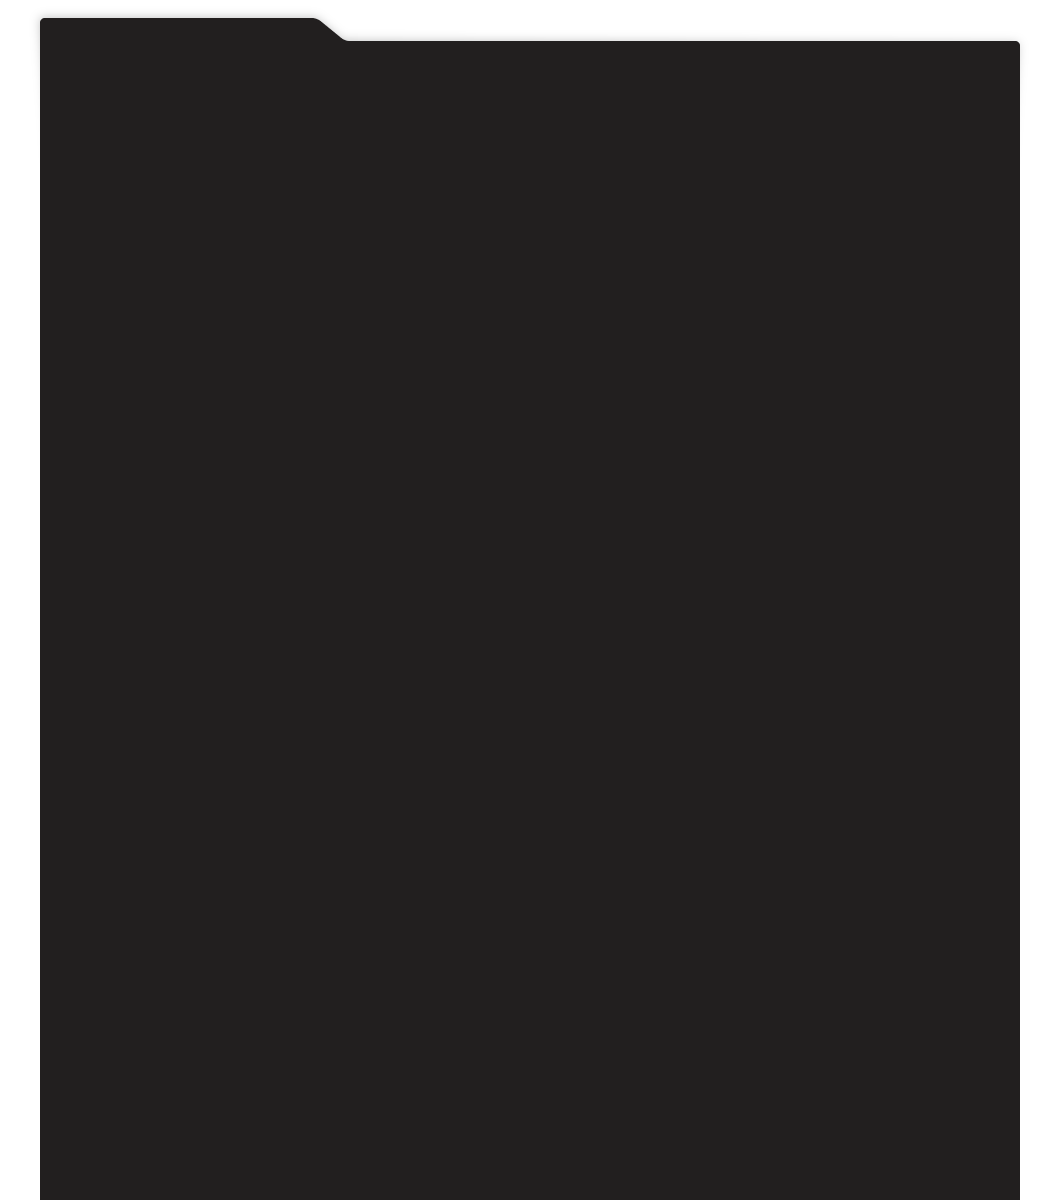
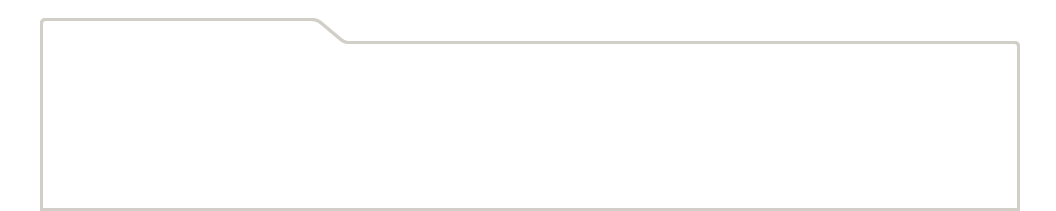
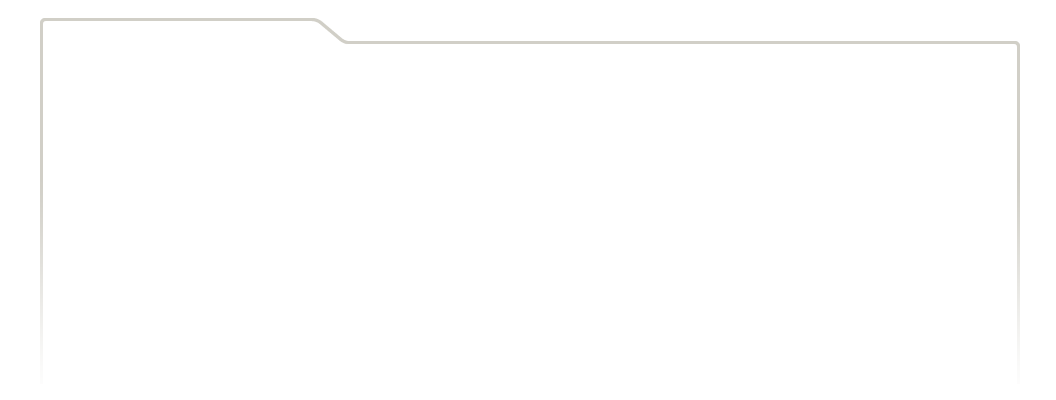
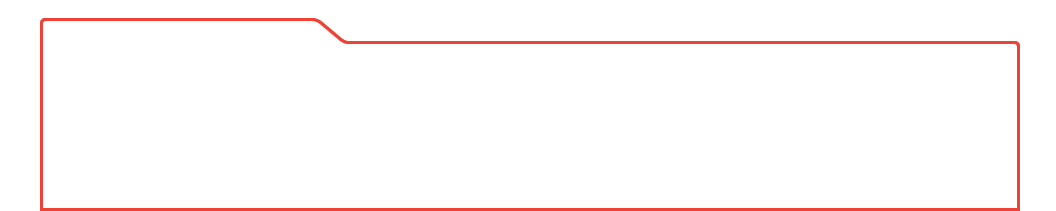
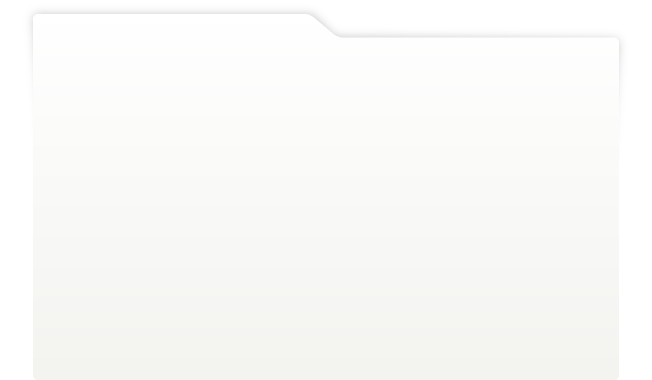
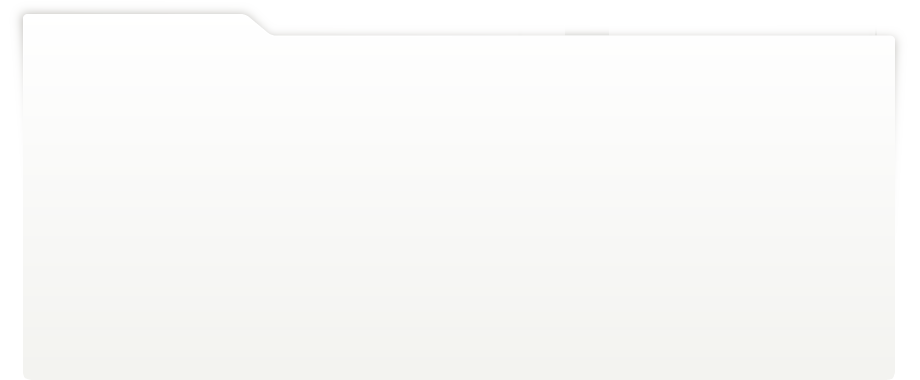
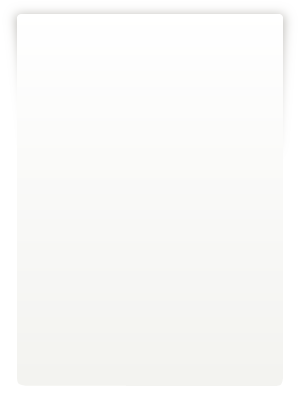
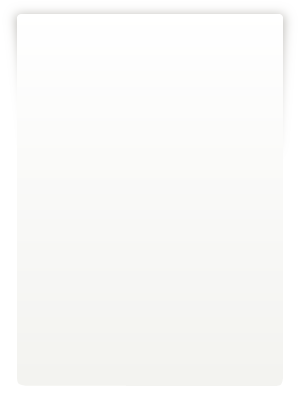
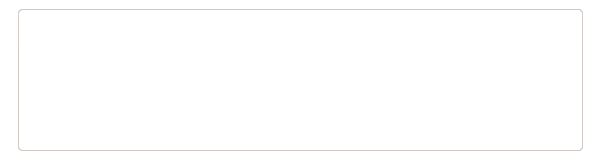
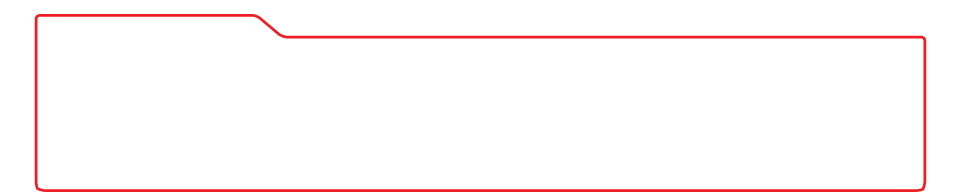
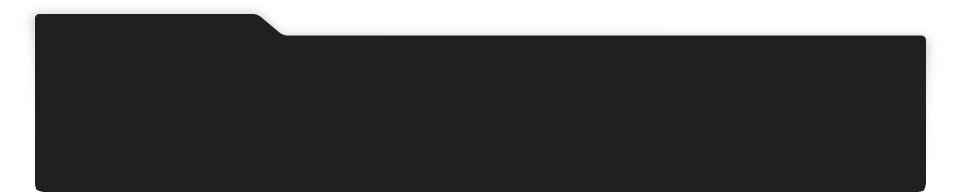
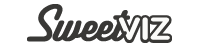
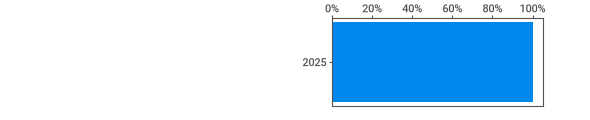
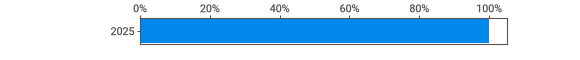
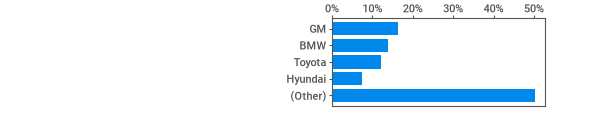
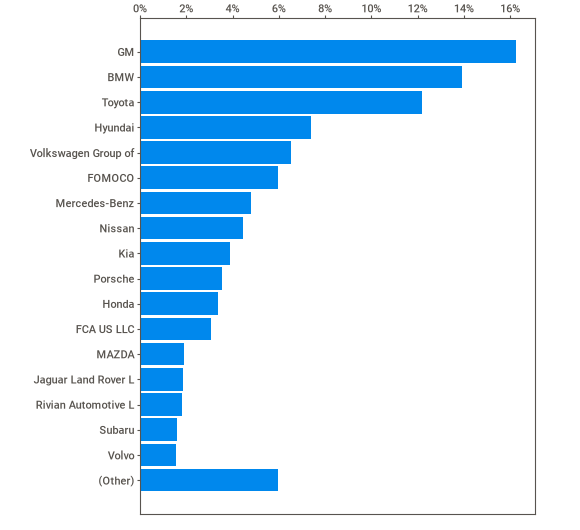
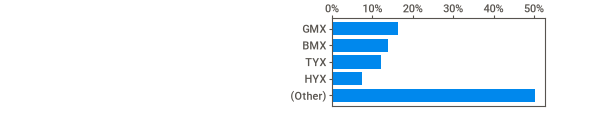
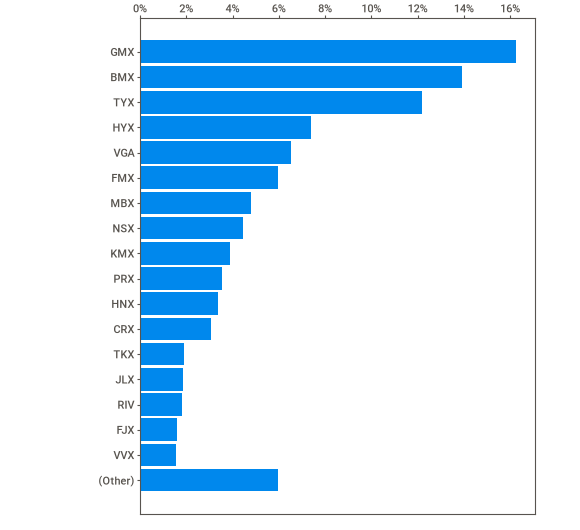
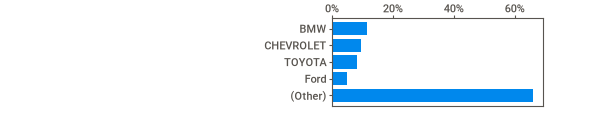
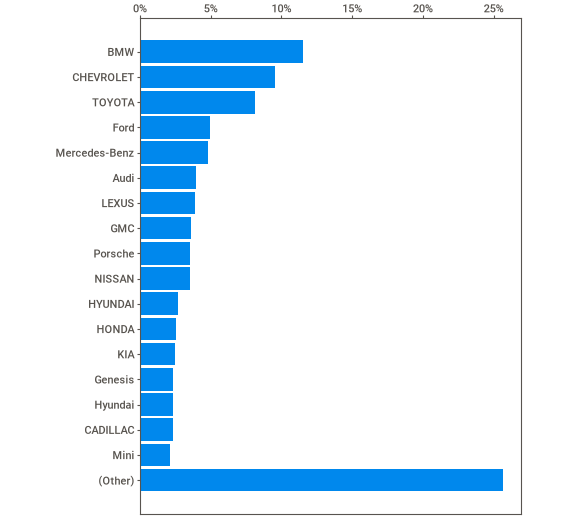
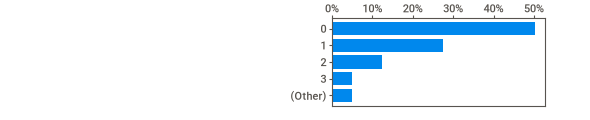
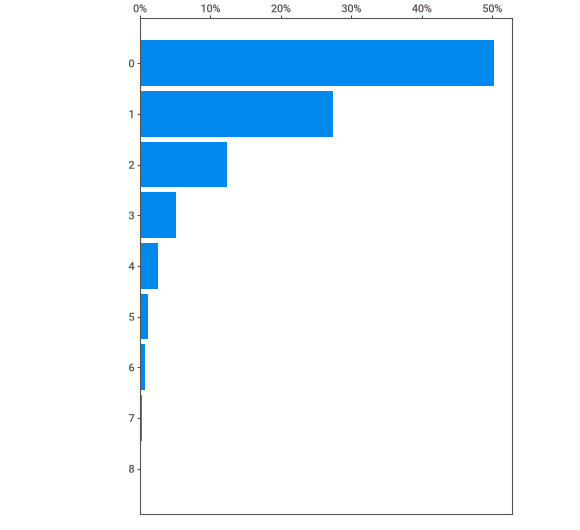
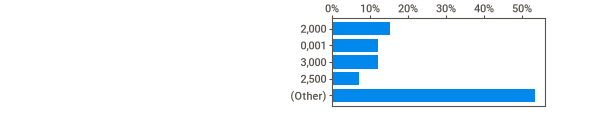
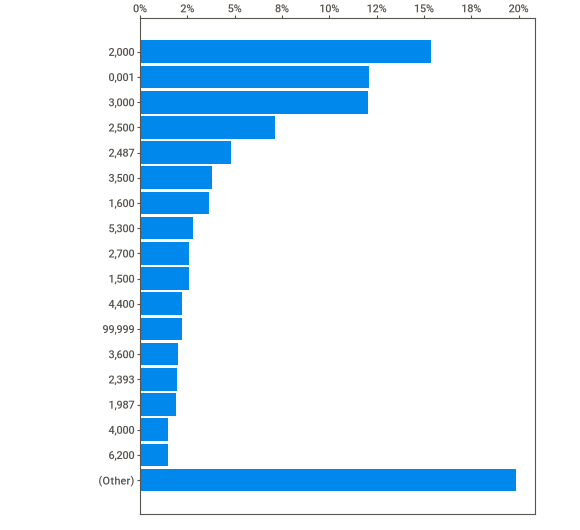
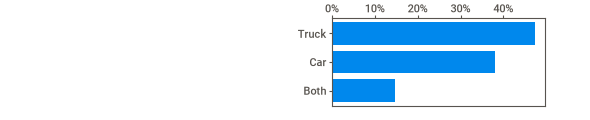
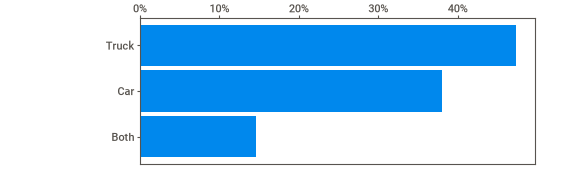
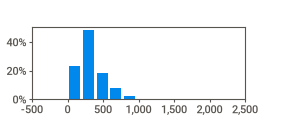
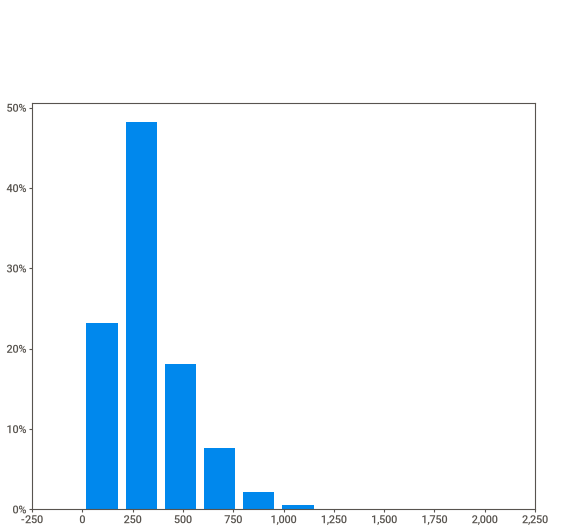
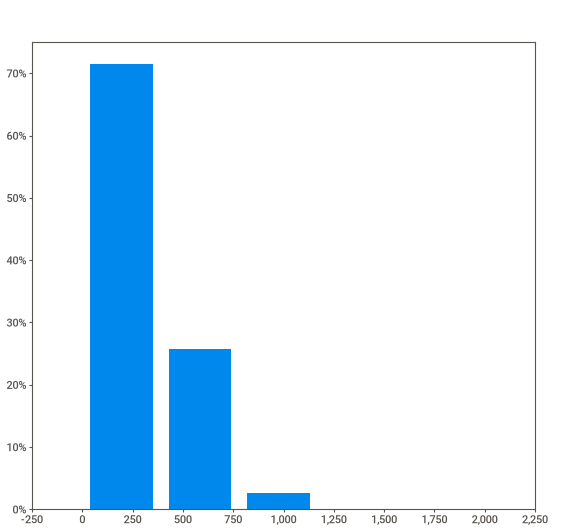
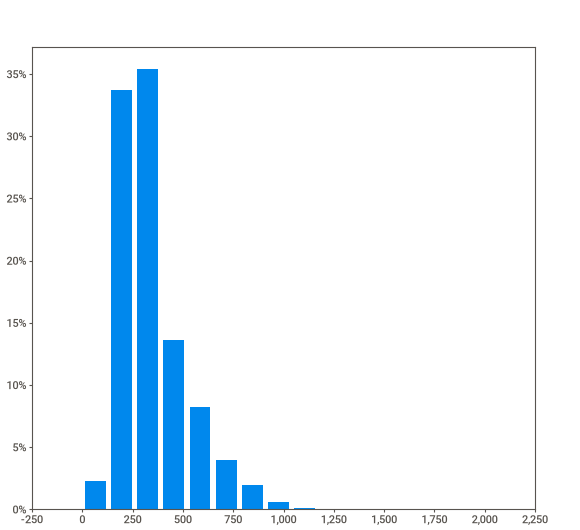
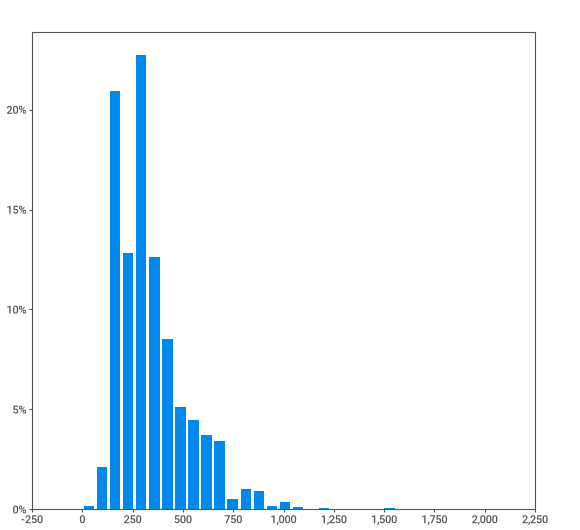
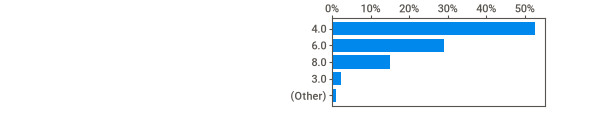
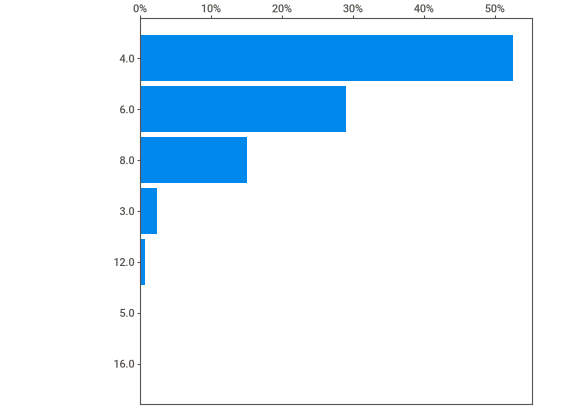
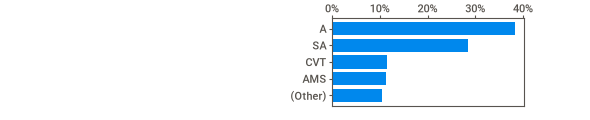
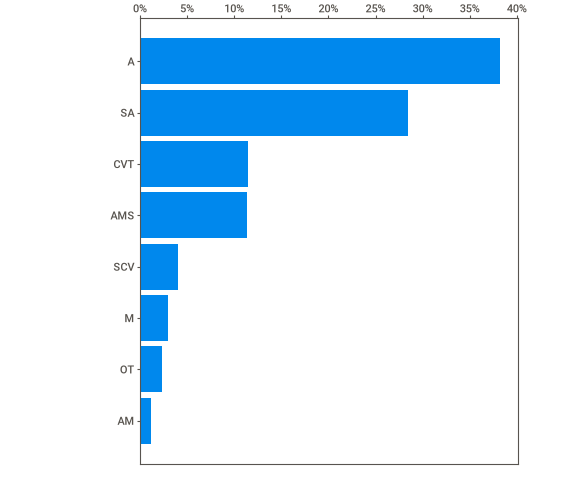
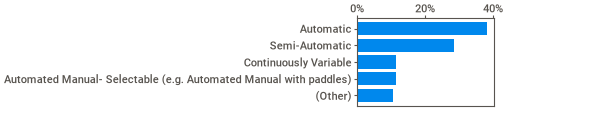
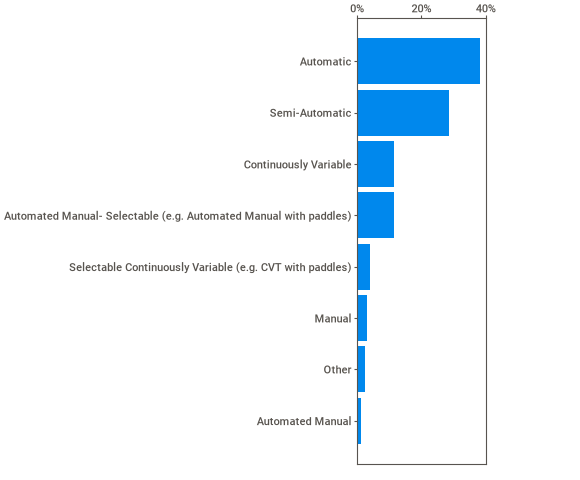
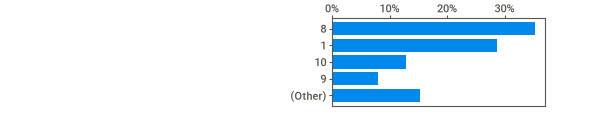
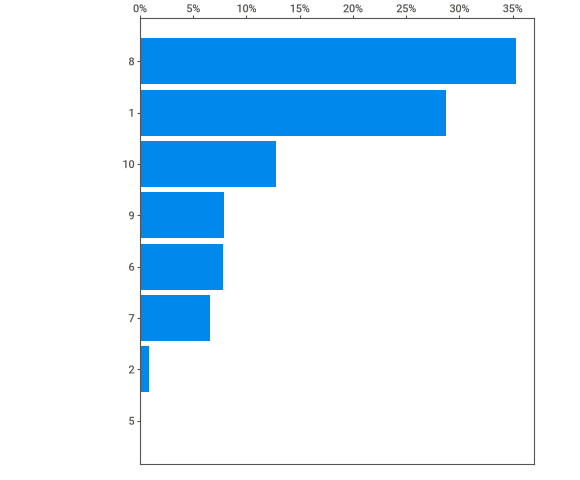
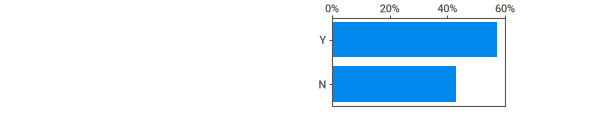
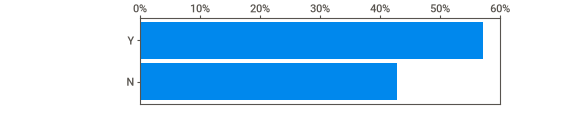
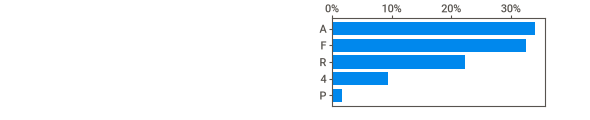
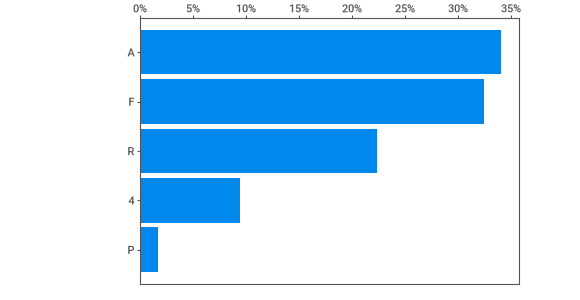
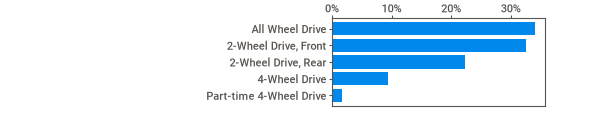
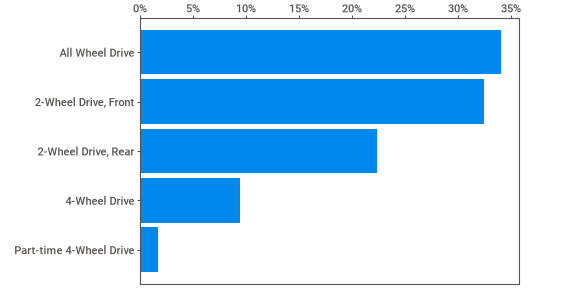
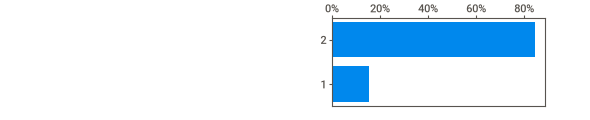
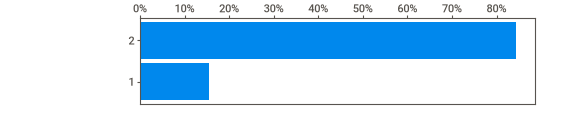
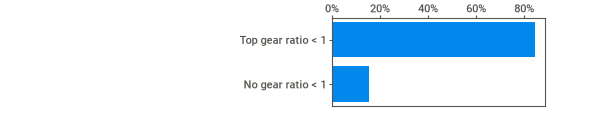
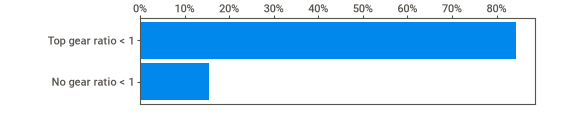
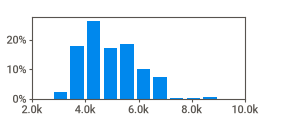
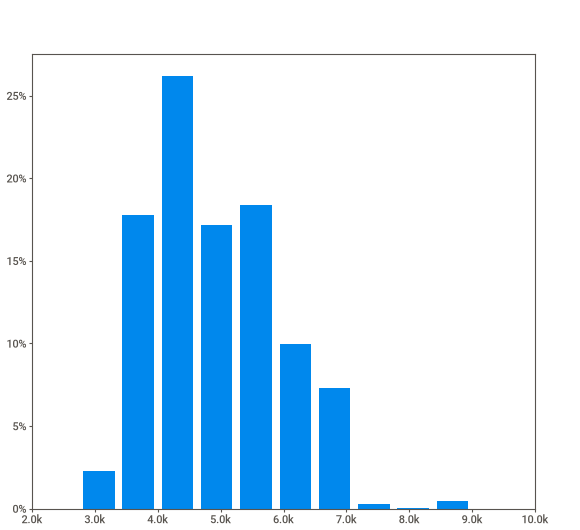
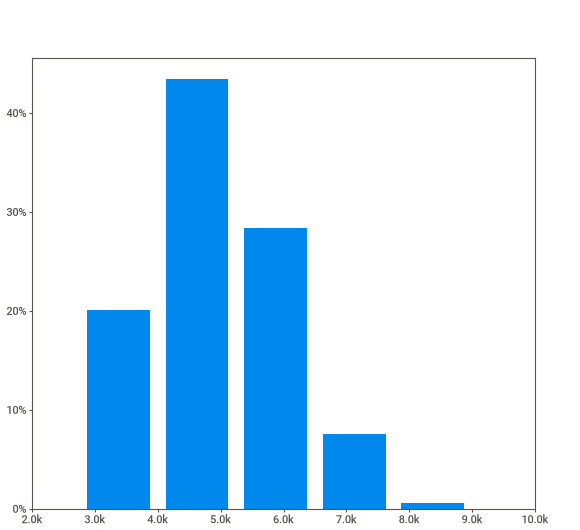
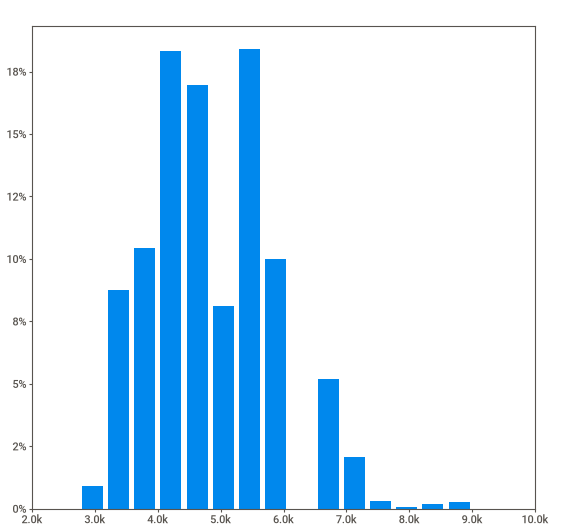
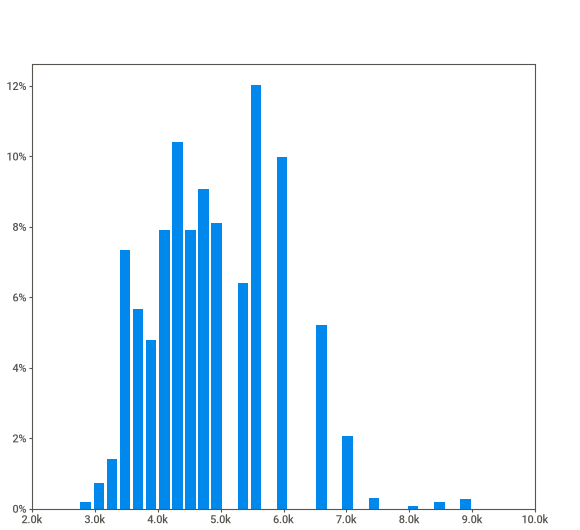
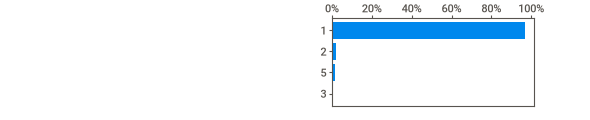
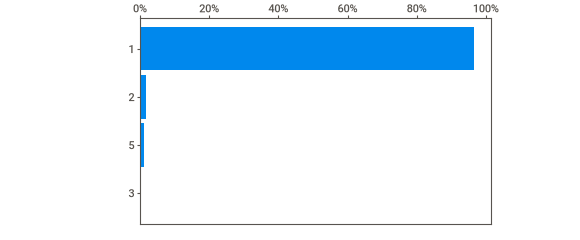
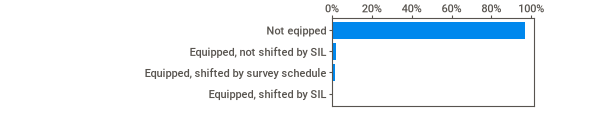
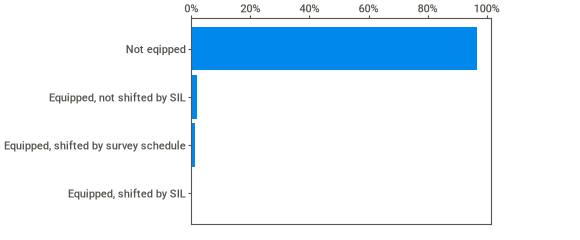
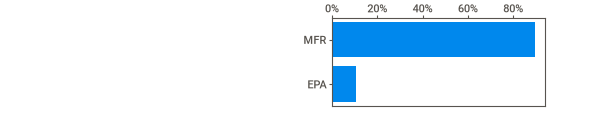
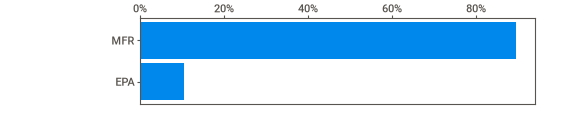
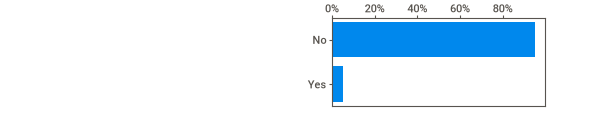
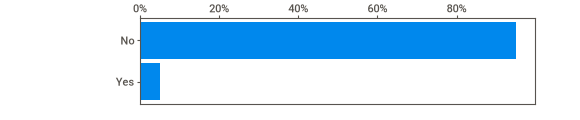
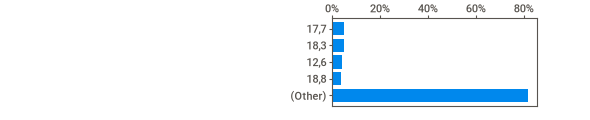
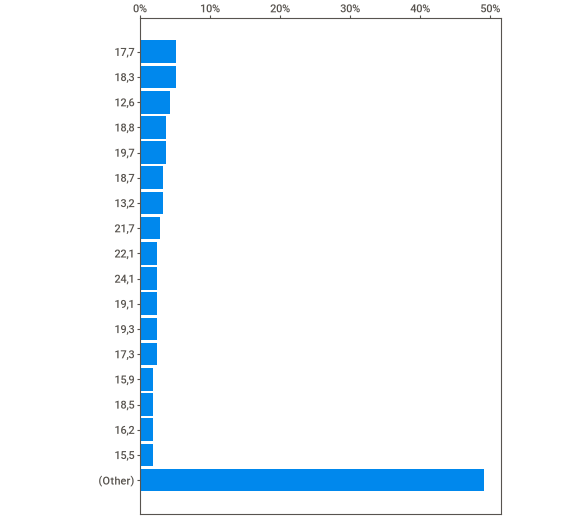
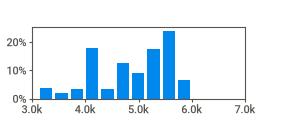
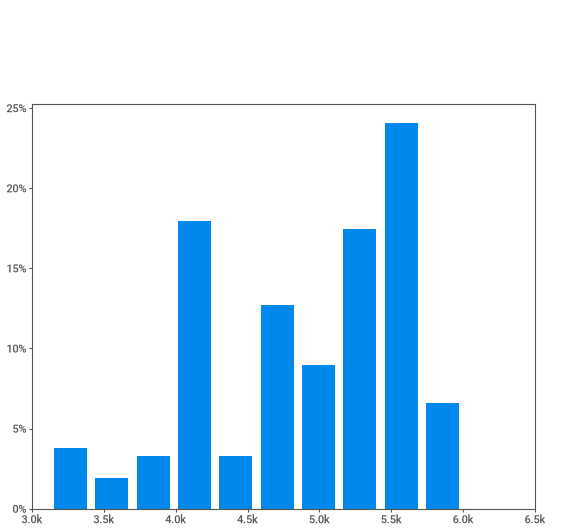
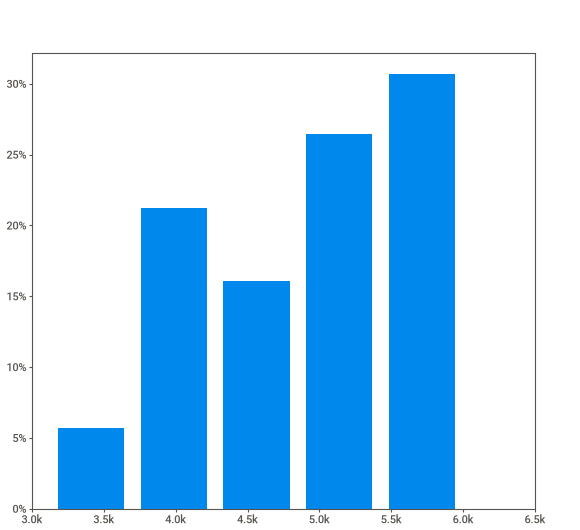
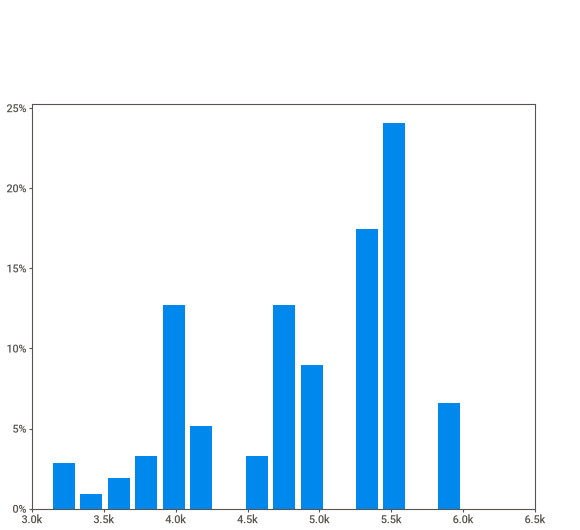
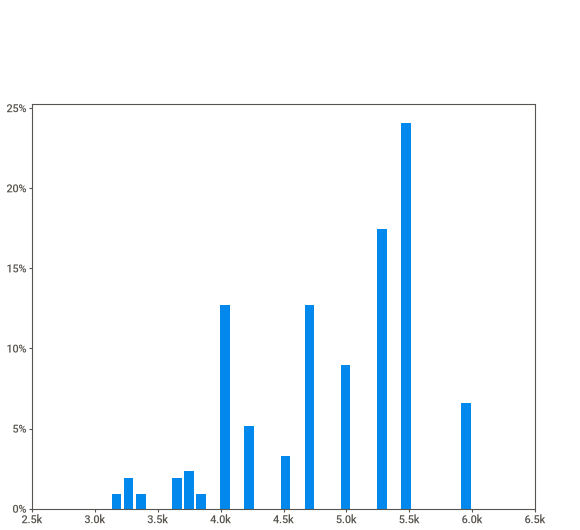
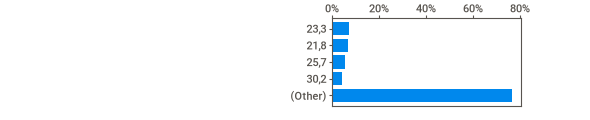
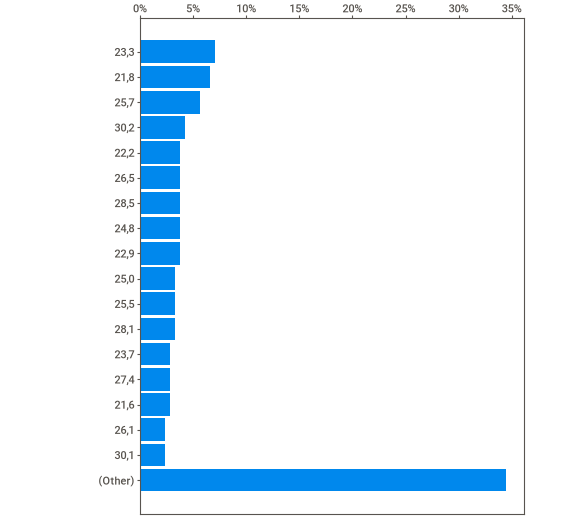
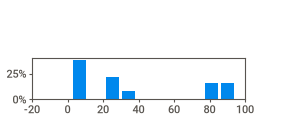
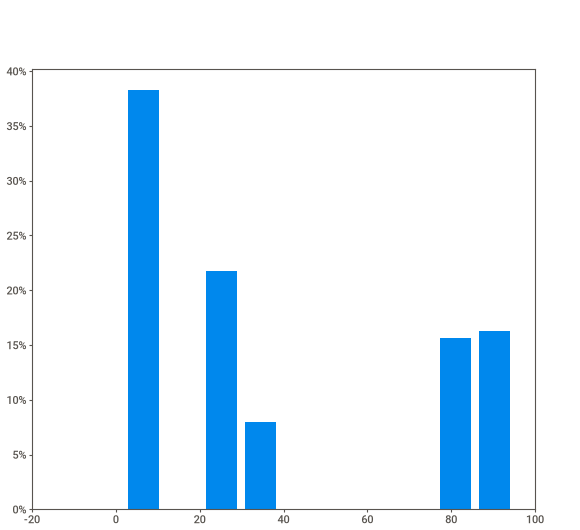
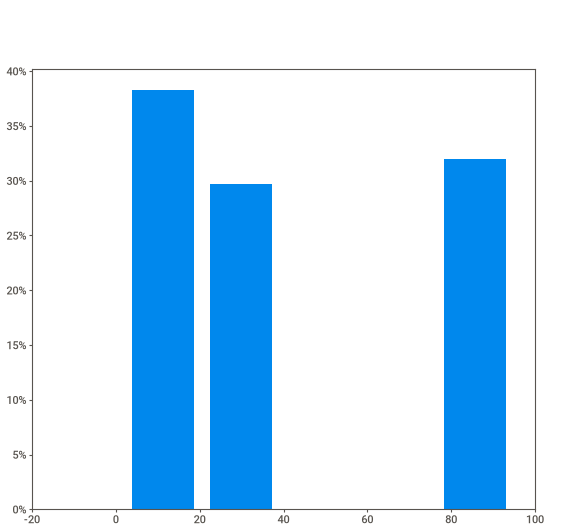
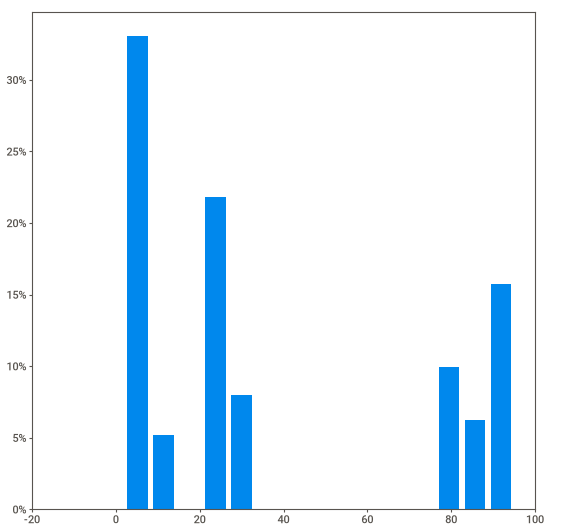
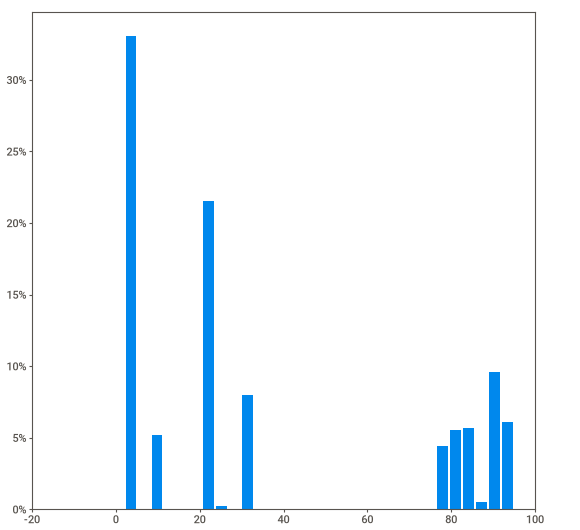
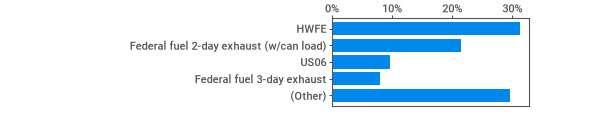
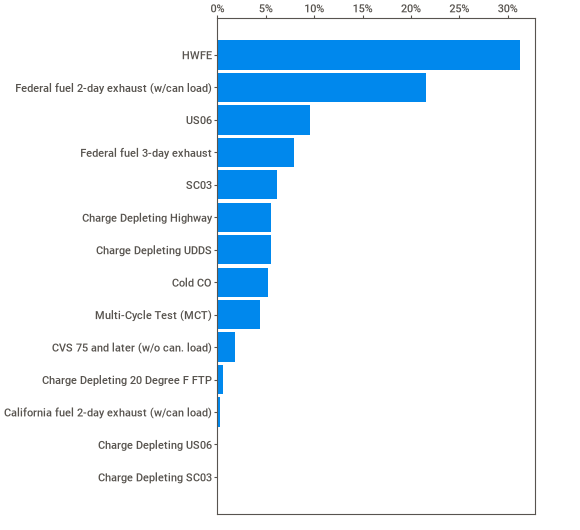
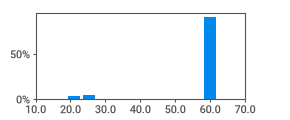
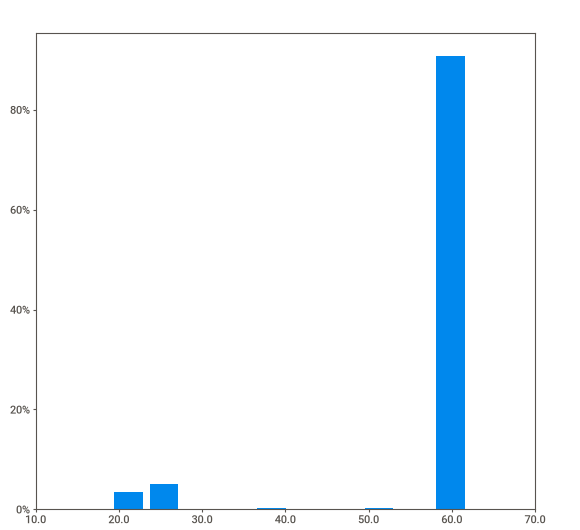
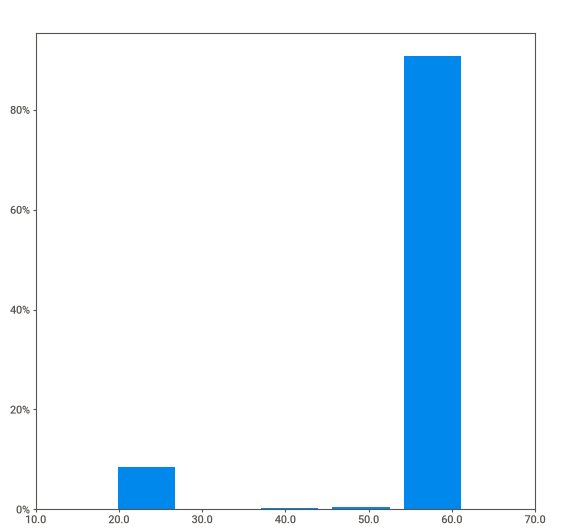
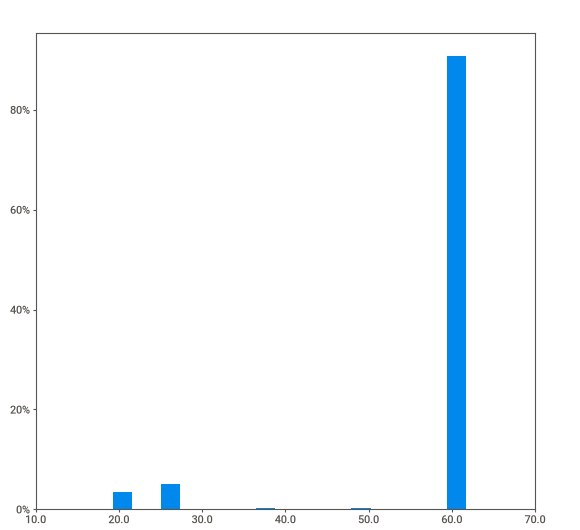
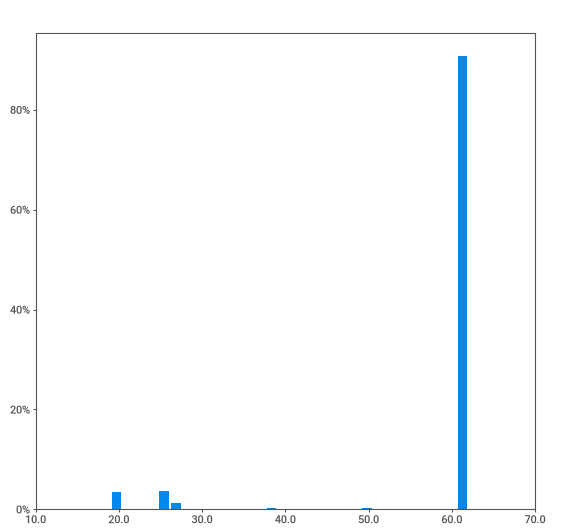
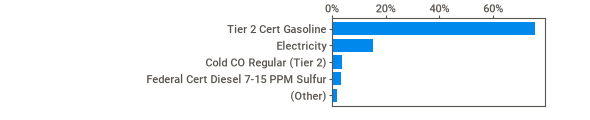
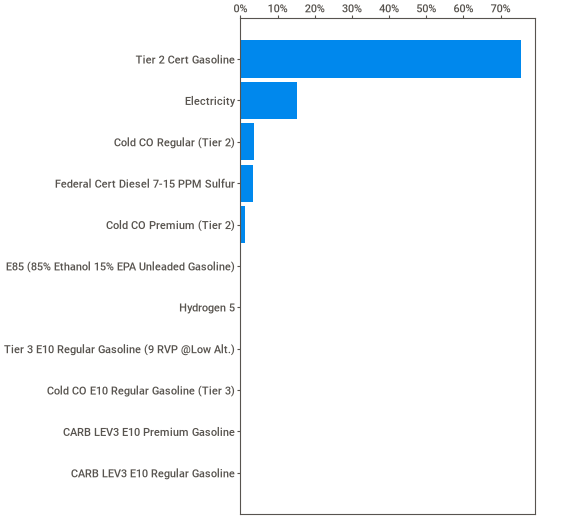
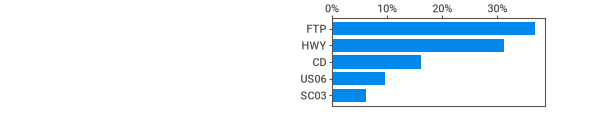
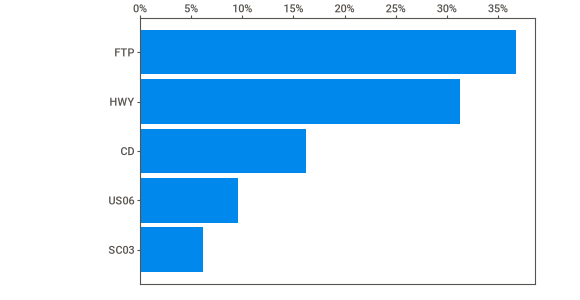
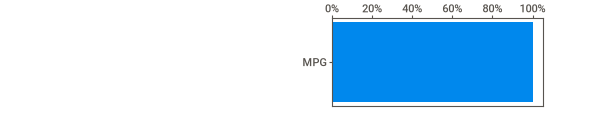
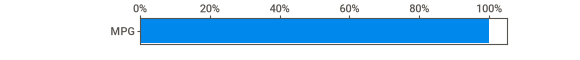
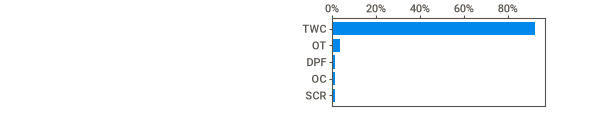
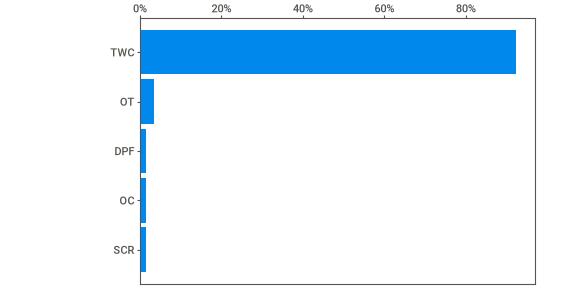
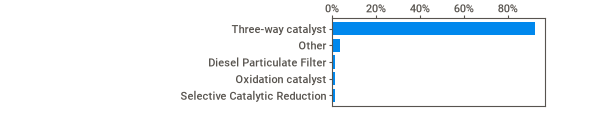
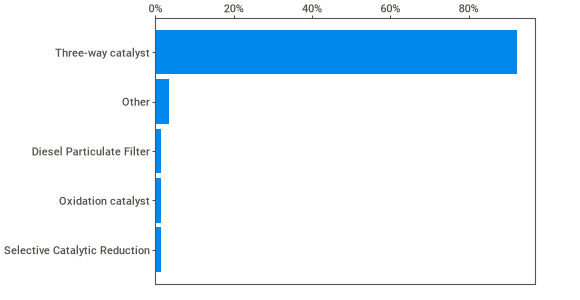
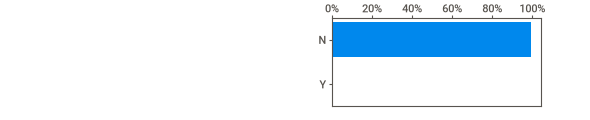
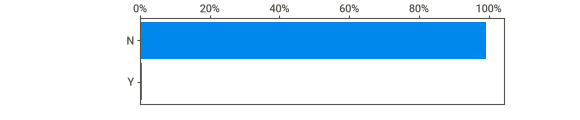
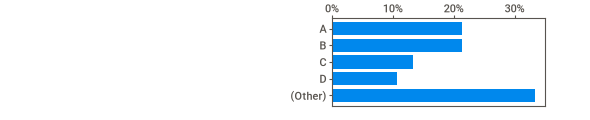
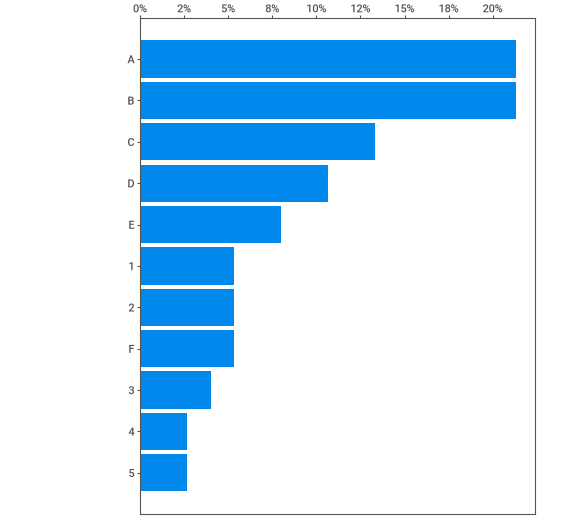
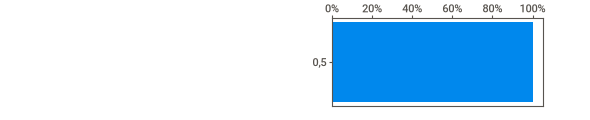
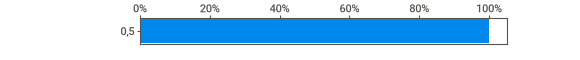
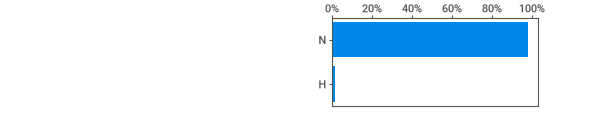
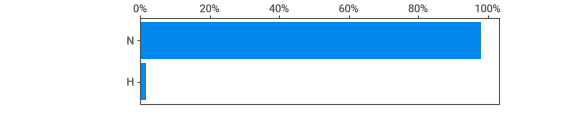
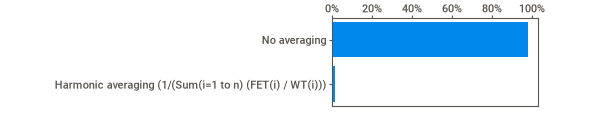
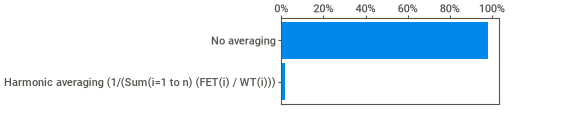
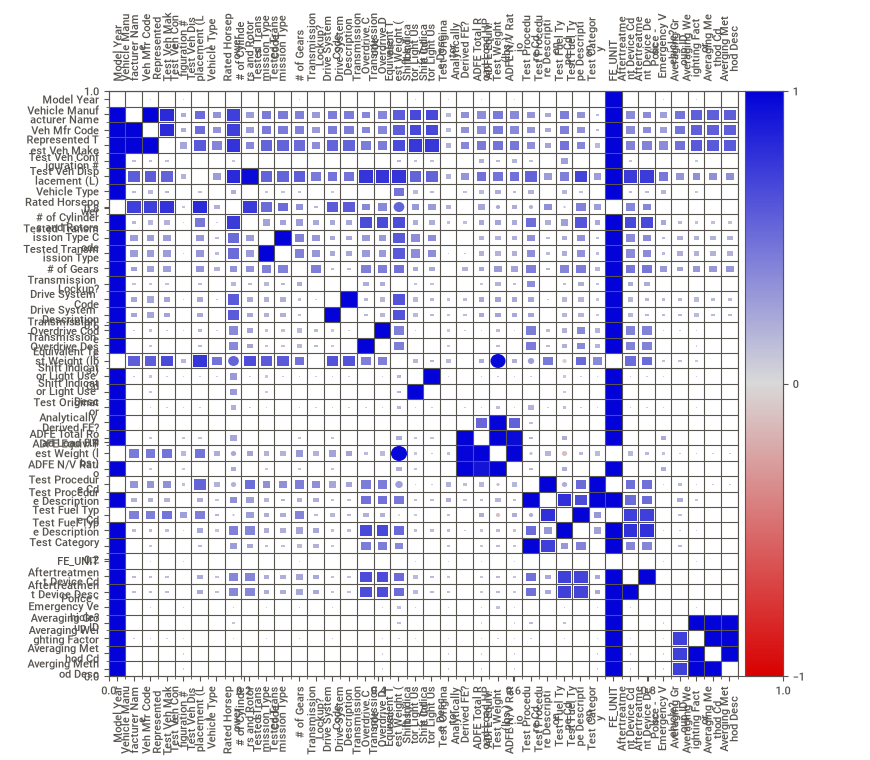
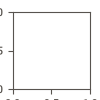

In [5]:
import sweetviz as sv

# Generar el análisis del DataFrame
reporte = sv.analyze(preprocessed_dataset)

# Mostrar el reporte dentro de la notebook
reporte.show_notebook()

## 3. Hipótesis

In [22]:
preprocessed_dataset["Test Fuel Type Description"].unique()

<StringArray>
[                         'Tier 2 Cert Gasoline',                      'Cold CO Premium (Tier 2)',                                   'Electricity',                      'Cold CO Regular (Tier 2)',
   'E85 (85% Ethanol 15% EPA Unleaded Gasoline)',           'Federal Cert Diesel 7-15 PPM Sulfur',                                    'Hydrogen 5',         'Cold CO E10 Regular Gasoline (Tier 3)',
 'Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)',                'CARB LEV3 E10 Regular Gasoline',                'CARB LEV3 E10 Premium Gasoline']
Length: 11, dtype: str

In [25]:
preprocessed_dataset["Test Category"].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Test Category
Non-Null Count  Dtype
--------------  -----
4287 non-null   str  
dtypes: str(1)
memory usage: 33.6 KB


#### Preprocesamiento de la variable RND_ADJ_FE

Analizando valores extremos

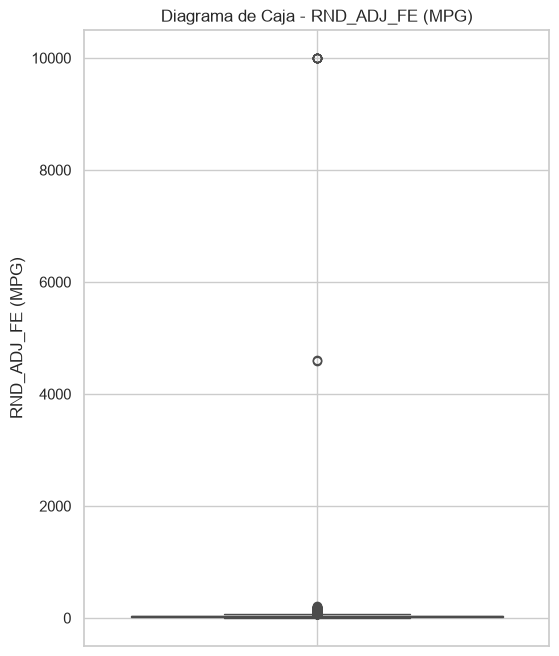

In [6]:
# Convertir la variable RND_ADJ_FE a numérico
preprocessed_dataset["RND_ADJ_FE"] = (
    preprocessed_dataset["RND_ADJ_FE"].astype(str).str.replace(",", ".", regex=False)
)
preprocessed_dataset["RND_ADJ_FE"] = pd.to_numeric(preprocessed_dataset["RND_ADJ_FE"], errors="coerce")
preprocessed_dataset["RND_ADJ_FE"] = preprocessed_dataset["RND_ADJ_FE"].replace(999.0, np.nan)

# Crear el gráfico boxplot
plt.figure(figsize=(6, 8))
sns.boxplot(y=df["RND_ADJ_FE"])
plt.title("Diagrama de Caja - RND_ADJ_FE (MPG)")
plt.ylabel("RND_ADJ_FE (MPG)")
plt.grid(True)
plt.show()

Reemplazamos los valores extremos por NaN, normalizamos el separador decimal para convetirla en float, Reemplazamos los valores extremos

In [38]:
# 1. Normalizar separador decimal (reemplazar comas por puntos)
preprocessed_dataset["RND_ADJ_FE"] = preprocessed_dataset["RND_ADJ_FE"].astype(str).str.replace(",", ".", regex=False)

# 2. Convertir a tipo de dato numérico (float)
preprocessed_dataset["RND_ADJ_FE"] = pd.to_numeric(preprocessed_dataset["RND_ADJ_FE"], errors="coerce")

# 2. Reemplazar únicamente códigos de error (ej. 999) y valores imposibles por NaN
preprocessed_dataset.loc[
    (preprocessed_dataset["RND_ADJ_FE"] <= 0)
    | (preprocessed_dataset["RND_ADJ_FE"] == 999.0)
    | (preprocessed_dataset["RND_ADJ_FE"] > 500),
    "RND_ADJ_FE",
] = np.nan

## 4. Validación de hipótesis

In [43]:
variables = [
    'Averaging Group ID',
    'Averaging Weighting Factor',
    'Averaging Method Cd',
    'Averging Method Desc'
]

tabla_variables = pd.DataFrame({
    'Variable': variables,
    'Valores': [
        preprocessed_dataset[col].dropna().unique().tolist()
        for col in variables
    ]
})

display(tabla_variables)

,Variable,Valores
0,Averaging Group ID,"[3, 4, 5, 1, 2, C, D, E, A, B, F]"
1,Averaging Weighting Factor,"[0,5]"
2,Averaging Method Cd,"[N, H]"
3,Averging Method Desc,"[No averaging, Harmonic averaging (1/(Sum(i=1 ..."


In [44]:
test_number_repetidos = preprocessed_dataset[
preprocessed_dataset['Test Number'].duplicated(keep=False)
].sort_values('Test Number')

In [45]:
columnas_diferentes = test_number_repetidos.columns[
test_number_repetidos.nunique(dropna=False) > 1
]

In [47]:
for numero, grupo in test_number_repetidos.groupby('Test Number'):
    columnas_diferentes = grupo.columns[
        grupo.nunique(dropna=False) > 1
    ]

    if len(columnas_diferentes) > 0:
        print(f"\nTest Number: {numero}")
        display(grupo[columnas_diferentes])


Test Number: NFEX10067550


,Aftertreatment Device Cd,Aftertreatment Device Desc
782,TWC,Three-way catalyst
783,OT,Other



Test Number: NFEX10067551


,Aftertreatment Device Cd,Aftertreatment Device Desc
784,TWC,Three-way catalyst
785,OT,Other



Test Number: NFEX10067679


,Aftertreatment Device Cd,Aftertreatment Device Desc
786,OT,Other
787,TWC,Three-way catalyst


... (416 outputs left out)


Test Number: SGMX91006218


,Aftertreatment Device Cd,Aftertreatment Device Desc
1502,OC,Oxidation catalyst
1500,DPF,Diesel Particulate Filter
1501,SCR,Selective Catalytic Reduction



Test Number: SGMX91006219


,Aftertreatment Device Cd,Aftertreatment Device Desc
1505,OC,Oxidation catalyst
1504,SCR,Selective Catalytic Reduction
1503,DPF,Diesel Particulate Filter
